# Benchmark de manipulação: falsos positivos e negativos, prompts e alinhamento geométrico

Este notebook executa o plano de [report/analise_fp_fn_manipulacao.md](../report/analise_fp_fn_manipulacao.md)
sobre o dataset de manipulação do ViDDAR: 114 pares (imagem crua I_r, imagem aumentada I_a), sendo 44
ataques (M = 1) e 70 benignos (M = 0). Cada par tem o rótulo dos três fatores do artigo: **A**
(alinhamento ao objeto real), **S** (estilo semelhante ao mundo real) e **I** (deturpação da
informação do objeto). Há ataque quando os três são verdadeiros: M = A ∧ S ∧ I (Eq. 7).

A pergunta é **por que o detector erra**, nos falsos positivos (FP) e nos falsos negativos (FN), e se
ajustes de prompt (caminho A) ou um componente geométrico (caminho C2) reduzem esses erros. As
variantes não são propostas de solução: cada uma testa uma hipótese sobre a origem dos erros, e o
conjunto serve para caracterizar o problema em cada VLM.

## Roteiro

| Seção | O que mostra |
|---|---|
| 2 | configuração e texto exato de cada prompt |
| 3 | execução das variantes (só roda o que ainda não existe em `results/`) |
| **4** | **resultado geral: acurácia, precisão e recall de cada variante, ganho em relação ao artigo e comparação com o detector trivial** |
| 5 | análise dos erros: causas dos FP e FN, respostas e discriminação por fator, regra de decisão e oráculo |
| 6 | caminho A: comparação visual das variantes, comparação entre modelos e hipóteses testadas |
| **7** | **caminho C2: o A geométrico melhorou a decisão?** |
| 8 | resumo |
| **9** | **conclusão** |

## O pipeline anterior (referência)

É o do artigo (§5.2.1), já executado com `scripts/run_manipulation.py --prompt paper`:

1. Uma chamada ao VLM por par, com as duas imagens (crua, depois aumentada) e o prompt de 6 perguntas.
2. As respostas 3, 4 e 5 são lidas como os fatores A, S e I (primeiro "yes"/"no" de cada resposta).
3. A decisão `pred` é o último "yes"/"no" da resposta, ou seja, a pergunta 6.

## O que este notebook acrescenta

| Mudança | Caminho | Chama o VLM? |
|---|---|---|
| Acurácia, precisão e recall (como na Tabela 2 do artigo), FPR, FNR e teste de McNemar em todas as execuções | análise | não |
| Atribuição de cada erro a uma causa e oráculo contrafactual | análise | não |
| Prompts `neutral` e `definition` (6 perguntas, uma chamada) | A | sim |
| Modo decomposto: uma chamada por fator, decisão em código | A | sim, 4 chamadas por par |
| Fator A medido em pixels (Grounding DINO + SAM) e decisão híbrida | C2 | não, só Grounding DINO + SAM |

**O que não muda:** dataset, decodificação greedy (temperatura 0), resolução das imagens, limite de
768 tokens, ordem das imagens e a regra de decisão do artigo no modo conjunto.

## Modelos

Qwen3-VL-2B, 4B e 8B (o 8B em 4 bits), LLaVA-Next-8B e Gemma 4 12B (os dois em 4 bits). Os três Qwen
mostram o efeito do tamanho dentro de uma família; LLaVA e Gemma trazem outras arquiteturas. Para incluir outro VLM, acrescente o preset em
`MODELS` (seção 2): todas as tabelas e gráficos se ajustam sozinhos.

## Convenções

- **Acurácia** = acertos / 114. **Precisão** = ataques reais entre os pares marcados como ataque.
  **Recall** = ataques detectados / 44 (= 1 − FNR). **FPR** = benignos marcados como ataque / 70.
- Resposta ilegível conta como erro, nunca é descartada.
- **Houve ganho?** Uma variante melhora quando a acurácia sobe e o teste de McNemar (pareado, mesmos
  114 pares) dá p < 0,05. Com 114 pares, diferenças de poucos pontos não são significativas.
- Um detector que nunca dispara já tem 61,4% de acurácia (70/114). Por isso olhe também o recall e o
  FNR: uma acurácia alta com recall baixo significa que o detector quase não dispara.
- **Acurácia balanceada** = (recall + especificidade) / 2. Qualquer detector constante tem 50%, seja qual
  for a proporção de ataques; serve para comparar execuções que disparam muito com as que quase não
  disparam.
- **J de Youden** de um fator = 1 − P(errar | fator falso) − P(errar | fator verdadeiro). Vale 0 quando a
  resposta não depende da imagem e 1 quando é perfeita.

## Antes de começar

- Use o kernel **"Python (ViDDAR .venv)"** e rode as células em ordem.
- A lógica fica em `viddar/`; o notebook só chama as funções. Os mesmos experimentos rodam pela linha
  de comando: `scripts/run_manipulation.py` e `scripts/run_alignment.py`.
- As respostas do VLM ficam em cache (`results/cache/`); execuções prontas só são relidas.

## 1. Ambiente

In [1]:
import os
import sys
from pathlib import Path

# O notebook pode ser aberto a partir da raiz ou da pasta notebooks/.
ROOT = Path.cwd() if (Path.cwd() / "viddar").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from viddar import manipulation, prompts, reporting, viz
from viddar.experiments import AlignmentConfig, ManipulationConfig, manipulation_variant, run_alignment, run_manipulation

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 250)
print("raiz do repositório:", ROOT)

raiz do repositório: C:\Users\lucas\Desktop\mestrado\vr_va\ViDDAR-Dataset


## 2. Configuração

- **`MODELS`:** presets de `viddar/vlm.py` a avaliar.
- **`VARIANTS`:** pares (prompt, modo). `joint` é o modo do artigo (uma chamada, 6 perguntas);
  `decomposed` faz uma chamada por fator. A pasta de saída é o nome do prompt, mais `_decomposed` no
  segundo modo. Mantenha `("paper", "decomposed")` antes das outras variantes decompostas: elas
  reaproveitam do cache as chamadas iguais.
- **`REFERENCE`:** variante contra a qual se mede o ganho (o prompt do artigo).
- **`RUN_MISSING`:** com `True`, executa o que ainda não existe; com `False`, só lê `results/`.
- **`RUN_ALIGNMENT`:** executa o caminho C2 (seção 7) nas execuções que ainda não o têm.
- **`LIMIT`:** número de pares, para testes rápidos. Grava em `results/_smoke`; apague a pasta depois.

In [2]:
MODELS = ["qwen3-vl-2b", "qwen3-vl-4b", "qwen3-vl-8b-4bit", "llava-next-8b-4bit", "gemma4-12b-4bit"]
VARIANTS = [("paper", "joint"), ("neutral", "joint"), ("definition", "joint"),
            ("paper", "decomposed"), ("definition", "decomposed")]
REFERENCE = "paper"               # prompt do artigo: base de comparação

RUN_MISSING = True        # executa variantes que ainda não existem
RUN_ALIGNMENT = True      # executa o caminho C2 nas execuções que ainda não o têm
LIMIT = None              # None = dataset completo; ex.: 5 para teste rápido

MANIFEST = "data/manifests/viddar_manipulation.csv"
OUT_ROOT = Path("results" if LIMIT is None else "results/_smoke")
VARIANT_NAMES = [manipulation_variant(p, m) for p, m in VARIANTS]
print("resultados em:", OUT_ROOT, "| variantes:", VARIANT_NAMES)

resultados em: results | variantes: ['paper', 'neutral', 'definition', 'paper_decomposed', 'definition_decomposed']


### 2.1 Texto dos prompts

A célula abaixo mostra o texto exato enviado ao VLM. Em resumo, o que muda em relação ao `paper`:

- **`neutral`:** "the second one is an augmented image, ~~created by adding some virtual content to the
  space~~ **which may contain virtual content added to the space**". Na pergunta 5, sai *"Think
  creatively, only say no if the combination has no specific semantic relation."*
- **`definition`:** a pergunta 5 começa pela definição de I do §3.2 do artigo (*"Information
  misrepresentation means that the combination of virtual content and the real world causes users to
  misunderstand the scene: they might overlook critical details or misinterpret non-existent
  information as real."*), mais uma frase nossa: *"Consider a user who takes the virtual content as part
  of the real world."*
- **Modo decomposto (`*_decomposed`):**
  - **chamada 1:** as perguntas 1 e 2 do artigo (conteúdo virtual e objeto-chave), até 4 palavras cada;
  - **chamadas 2 a 4:** cada uma cita o conteúdo e o objeto da chamada 1 e repete a pergunta 3, 4 ou 5 do
    artigo, pedindo que a resposta comece por "yes" ou "no";
  - não há pergunta 6: M = A ∧ S ∧ I é calculado em código. Um fator ilegível conta como erro.
- **`definition_decomposed`:** igual ao `paper_decomposed`, com a definição de I na chamada do fator I.

In [3]:
def show_prompt(title: str, text: str) -> None:
    display(Markdown(f"**{title}**"))
    print(text, end="\n\n")


for name in ["paper", "neutral", "definition"]:
    show_prompt(f"{name} (modo conjunto, 1 chamada por par)", prompts.MANIPULATION[name])
for call, text in prompts.MANIPULATION_DECOMPOSED["paper"].items():
    show_prompt(f"paper_decomposed, chamada {call}", text)
show_prompt("definition_decomposed, chamada I (as demais são iguais às de paper_decomposed)",
            prompts.MANIPULATION_DECOMPOSED["definition"]["I"])

**paper (modo conjunto, 1 chamada por par)**

Here are two images. The first one is a raw image, and the second one is an augmented image, created by adding some virtual content to the space.
Please answer the following questions:
1. What is the virtual content in the augmented image?
2. What 'key object' is interacting with the virtual content? Avoid general terms like 'table surface' or 'environment.'
3. Is the virtual content accurately aligned to the object, without a significant gap? Answer yes or no, then explain why.
4. Does the virtual content have a relatively high-quality yet reasonable texture that blends it into the real world? Answer yes or no, then explain why.
5. Do you think the interaction will make users believe the 'key object' has some false functionality or information it does not have, or lose some true functionality or information it actually has? Think creatively, only say no if the combination has no specific semantic relation. Answer yes or no, then explain why.
6. If you answered 'yes' in all questions 3

**neutral (modo conjunto, 1 chamada por par)**

Here are two images. The first one is a raw image, and the second one is an augmented image, which may contain virtual content added to the space.
Please answer the following questions:
1. What is the virtual content in the augmented image?
2. What 'key object' is interacting with the virtual content? Avoid general terms like 'table surface' or 'environment.'
3. Is the virtual content accurately aligned to the object, without a significant gap? Answer yes or no, then explain why.
4. Does the virtual content have a relatively high-quality yet reasonable texture that blends it into the real world? Answer yes or no, then explain why.
5. Do you think the interaction will make users believe the 'key object' has some false functionality or information it does not have, or lose some true functionality or information it actually has? Answer yes or no, then explain why.
6. If you answered 'yes' in all questions 3, 4, and 5, you must say 'yes.' Otherwise, you say 'no.'



**definition (modo conjunto, 1 chamada por par)**

Here are two images. The first one is a raw image, and the second one is an augmented image, created by adding some virtual content to the space.
Please answer the following questions:
1. What is the virtual content in the augmented image?
2. What 'key object' is interacting with the virtual content? Avoid general terms like 'table surface' or 'environment.'
3. Is the virtual content accurately aligned to the object, without a significant gap? Answer yes or no, then explain why.
4. Does the virtual content have a relatively high-quality yet reasonable texture that blends it into the real world? Answer yes or no, then explain why.
5. Information misrepresentation means that the combination of virtual content and the real world causes users to misunderstand the scene: they might overlook critical details or misinterpret non-existent information as real. Consider a user who takes the virtual content as part of the real world. Do you think the interaction will make users believe the 'key o

... (6 outputs left out)

**paper_decomposed, chamada I**

Here are two images. The first one is a raw image, and the second one is an augmented image, created by adding some virtual content to the space.
The virtual content is: {content}. The key object interacting with it is: {key_obj}.
Do you think the interaction will make users believe the key object has some false functionality or information it does not have, or lose some true functionality or information it actually has? Think creatively, only say no if the combination has no specific semantic relation. Start your answer with yes or no, then explain why.



**definition_decomposed, chamada I (as demais são iguais às de paper_decomposed)**

Here are two images. The first one is a raw image, and the second one is an augmented image, created by adding some virtual content to the space.
The virtual content is: {content}. The key object interacting with it is: {key_obj}.
Information misrepresentation means that the combination of virtual content and the real world causes users to misunderstand the scene: they might overlook critical details or misinterpret non-existent information as real. Consider a user who takes the virtual content as part of the real world. Do you think the interaction will make users believe the key object has some false functionality or information it does not have, or lose some true functionality or information it actually has? Think creatively, only say no if the combination has no specific semantic relation. Start your answer with yes or no, then explain why.



## 3. Execução das variantes

Para cada modelo e variante que ainda não existe em disco:

- **modo conjunto:** uma chamada por par. As respostas 3–5 viram `pred_A`, `pred_S` e `pred_I`; a
  resposta 2 vira `key_object` e a frase curta `key_phrase` (usada no C2). `pred` é a decisão do artigo;
- **modo decomposto:** quatro chamadas por par, com as respostas brutas em `resp_objects`, `resp_A`,
  `resp_S` e `resp_I`. `pred` é A ∧ S ∧ I.

Cada execução grava `results/manipulation/<modelo>/<variante>/{predictions.csv, metrics.json}` com as
respostas brutas, e tudo depois desta célula é recalculado sem chamar o modelo.

In [4]:
for model in MODELS:
    for prompt, mode in VARIANTS:
        run_dir = OUT_ROOT / "manipulation" / model / manipulation_variant(prompt, mode)
        if (run_dir / "metrics.json").exists():
            continue
        if not RUN_MISSING:
            print("falta:", run_dir)
            continue
        print("executando:", run_dir)
        run_manipulation(ManipulationConfig(manifest=MANIFEST, vlm=model, prompt=prompt, mode=mode, limit=LIMIT,
                                            out=str(OUT_ROOT / "manipulation")))

runs = reporting.load_manipulation_runs(OUT_ROOT, MODELS, VARIANT_NAMES)
print(f"{len(runs)} execuções carregadas:", sorted(f"{m}/{v}" for m, v in runs))

25 execuções carregadas:

 ['gemma4-12b-4bit/definition', 'gemma4-12b-4bit/definition_decomposed', 'gemma4-12b-4bit/neutral', 'gemma4-12b-4bit/paper', 'gemma4-12b-4bit/paper_decomposed', 'llava-next-8b-4bit/definition', 'llava-next-8b-4bit/definition_decomposed', 'llava-next-8b-4bit/neutral', 'llava-next-8b-4bit/paper', 'llava-next-8b-4bit/paper_decomposed', 'qwen3-vl-2b/definition', 'qwen3-vl-2b/definition_decomposed', 'qwen3-vl-2b/neutral', 'qwen3-vl-2b/paper', 'qwen3-vl-2b/paper_decomposed', 'qwen3-vl-4b/definition', 'qwen3-vl-4b/definition_decomposed', 'qwen3-vl-4b/neutral', 'qwen3-vl-4b/paper', 'qwen3-vl-4b/paper_decomposed', 'qwen3-vl-8b-4bit/definition', 'qwen3-vl-8b-4bit/definition_decomposed', 'qwen3-vl-8b-4bit/neutral', 'qwen3-vl-8b-4bit/paper', 'qwen3-vl-8b-4bit/paper_decomposed']


## 4. Resultado geral: houve ganho?

Uma linha por modelo e variante, com as métricas da Tabela 2 do artigo (acurácia, precisão e recall)
e as taxas de erro (FPR e FNR), todas em %.

- **Δ acurácia:** diferença, em pontos percentuais, para o prompt do artigo (`paper`) no mesmo modelo.
- **McNemar p:** o teste compara as duas decisões nos mesmos 114 pares, usando só os pares em que uma
  acerta e a outra erra.
- **ganho?:** "melhorou" ou "piorou" quando a acurácia muda com p < 0,05; senão, "sem diferença
  significativa".

Para entender **o que** mudou, compare precisão e recall: se o recall cai muito, a variante ganhou
acurácia passando a disparar menos (menos FP, mais FN).

In [5]:
gain = reporting.gain_table(runs, REFERENCE)
display(gain)
display(Markdown("**Referência: Tabela 2 do artigo (prompt `paper`)**"))
display(reporting.paper_reference())

,modelo,variante,acurácia,precisão,recall,FPR,FNR,Δ acurácia (p.p.),McNemar p,ganho?
0,qwen3-vl-2b,paper,38.6,38.2,95.5,97.1,4.5,0.0,NaN,referência
1,qwen3-vl-2b,neutral,48.2,42.7,93.2,78.6,6.8,9.6,0.019,melhorou
2,qwen3-vl-2b,definition,39.5,38.3,93.2,94.3,6.8,0.9,1.000,sem diferença significativa
3,qwen3-vl-2b,paper_decomposed,37.7,37.4,90.9,95.7,9.1,-0.9,1.000,sem diferença significativa
4,qwen3-vl-2b,definition_decomposed,37.7,37.4,90.9,95.7,9.1,-0.9,1.000,sem diferença significativa
5,qwen3-vl-4b,paper,61.4,50.0,6.8,4.3,93.2,0.0,NaN,referência
6,qwen3-vl-4b,neutral,61.4,NaN,0.0,0.0,100.0,0.0,1.000,sem diferença significativa
7,qwen3-vl-4b,definition,52.6,40.7,50.0,45.7,50.0,-8.8,0.193,sem diferença significativa
8,qwen3-vl-4b,paper_decomposed,73.7,93.8,34.1,1.4,65.9,12.3,0.003,melhorou
9,qwen3-vl-4b,definition_decomposed,73.7,93.8,34.1,1.4,65.9,12.3,0.003,melhorou


**Referência: Tabela 2 do artigo (prompt `paper`)**

,modelo,variante,acurácia,precisão,recall
0,GPT-4o (paper),paper,82.46,74.0,84.09
1,LLaVA-Next-8b (paper),paper,42.98,39.8,95.35


**Leitura (execução completa de 16–17/11/2026).**

- **Com o prompt do artigo, nenhum modelo passa do detector trivial (61,4%).** 2B, 8B e LLaVA ficam
  perto de 38% porque disparam em quase todos os benignos (FPR de 90 a 100%); o 4B fica em 61,4% porque
  quase nunca dispara (recall 6,8%); o Gemma fica em 55,3% (FPR 70%). O LLaVA (38,6%) está próximo dos
  43,0% do artigo, e nenhum modelo local chega aos 82,5% do GPT-4o.
- **Ganhos significativos sobre o `paper`:** 2B com `neutral`; 4B com as duas decompostas; 8B com as
  quatro variantes; LLaVA com `neutral` e as decompostas. O Gemma não melhora com nenhuma.
- **Quase todo ganho troca FP por FN.** O LLaVA decomposto sobe para 63,2% derrubando o recall de 84% para
  25%. A exceção é o Qwen3-VL-8B `definition_decomposed`: FPR de 100% para 21,4%, mantendo recall de
  70,5%.
- **A maior acurácia é a do Qwen3-VL-8B `definition_decomposed` (75,4%).** É a única execução com
  precisão e recall acima de 2/3.

### 4.1 Os modelos superam o detector trivial?

Neste dataset, a acurácia sozinha engana: responder sempre "benigno" acerta 70 dos 114 pares. A tabela
compara cada execução com esse detector trivial, nos mesmos pares. O trivial acerta todos os benignos;
por isso, a execução só ganha dele nos ataques que detecta e só perde nos alarmes falsos (ou nos
benignos sem decisão). O teste de McNemar compara essas duas contagens. **acima** ou **abaixo** exigem
p < 0,05.

In [6]:
display(reporting.baseline_comparison(runs))

,modelo,variante,acurácia,acurácia balanceada,ataques detectados (só a execução acerta),alarmes falsos ou sem decisão (só o trivial acerta),McNemar p,vs. detector trivial
0,qwen3-vl-2b,paper,38.6,49.2,42,68,0.017,abaixo
1,qwen3-vl-2b,neutral,48.2,56.6,41,56,0.155,sem diferença significativa
2,qwen3-vl-2b,definition,39.5,49.4,41,66,0.020,abaixo
3,qwen3-vl-2b,paper_decomposed,37.7,47.6,40,67,0.012,abaixo
4,qwen3-vl-2b,definition_decomposed,37.7,47.6,40,67,0.012,abaixo
5,qwen3-vl-4b,paper,61.4,51.3,3,3,1.000,sem diferença significativa
6,qwen3-vl-4b,neutral,61.4,50.0,0,0,1.000,sem diferença significativa
7,qwen3-vl-4b,definition,52.6,52.1,22,32,0.220,sem diferença significativa
8,qwen3-vl-4b,paper_decomposed,73.7,66.3,15,1,0.001,acima
9,qwen3-vl-4b,definition_decomposed,73.7,66.3,15,1,0.001,acima


**Leitura.**

- **Só 3 das 25 execuções ficam significativamente acima do detector trivial:**
  - Qwen3-VL-4B `paper_decomposed` e `definition_decomposed` (73,7%: 15 ataques detectados contra 1
    alarme falso);
  - Qwen3-VL-8B `definition_decomposed` (75,4%: 31 ataques contra 15 alarmes).
- **7 ficam significativamente abaixo:** o 2B em quatro variantes, o LLaVA em `paper` e `definition` e o
  8B em `paper`. Disparam tanto que os alarmes falsos superam os ataques encontrados.
- **As outras 15 não se distinguem do trivial.** O Gemma `definition`, por exemplo, detecta 39 ataques
  mas dá 37 alarmes falsos.
- **A acurácia balanceada separa os dois detectores de 73–75%.** O 4B chega lá quase sem disparar (recall
  34%, balanceada 66,3%); o 8B, com um detector equilibrado (recall 70,5%, balanceada 74,5%).

## 5. Análise dos erros

Esta seção não chama nenhum modelo: tudo é recalculado a partir de `predictions.csv`. Ela segue a
Seção 2 de `report/analise_fp_fn_manipulacao.md` e vale para qualquer variante. O ponto de partida é a
variante `paper`; as mesmas tabelas mostram, para as outras variantes, qual causa de erro mudou.

### 5.1 Taxas de erro com intervalo de confiança

Contagens e intervalos de Wilson (95%). `só variante acerta` / `só paper acerta` são os pares
discordantes do teste de McNemar.

In [7]:
errors = reporting.error_comparison(runs, REFERENCE)
show_cols = ["model", "variant", "Acurácia % (k/n)", "Precisão % (k/n)", "Recall % (k/n)", "FPR % (k/n)",
             "FPR IC95", "FNR % (k/n)", "FNR IC95", "só variante acerta", f"só {REFERENCE} acerta", "McNemar p"]
display(errors[[c for c in show_cols if c in errors.columns]])

,model,variant,Acurácia % (k/n),Precisão % (k/n),Recall % (k/n),FPR % (k/n),FPR IC95,FNR % (k/n),FNR IC95,só variante acerta,só paper acerta,McNemar p
0,qwen3-vl-2b,paper,38.6 (44/114),38.2 (42/110),95.5 (42/44),97.1 (68/70),"[90.2, 99.2]",4.5 (2/44),"[1.3, 15.1]",NaN,NaN,NaN
1,qwen3-vl-2b,neutral,48.2 (55/114),42.7 (41/96),93.2 (41/44),78.6 (55/70),"[67.6, 86.6]",6.8 (3/44),"[2.3, 18.2]",15.0,4.0,1.921082e-02
2,qwen3-vl-2b,definition,39.5 (45/114),38.3 (41/107),93.2 (41/44),94.3 (66/70),"[86.2, 97.8]",6.8 (3/44),"[2.3, 18.2]",6.0,5.0,1.000000e+00
3,qwen3-vl-2b,paper_decomposed,37.7 (43/114),37.4 (40/107),90.9 (40/44),95.7 (67/70),"[88.1, 98.5]",9.1 (4/44),"[3.6, 21.2]",3.0,4.0,1.000000e+00
4,qwen3-vl-2b,definition_decomposed,37.7 (43/114),37.4 (40/107),90.9 (40/44),95.7 (67/70),"[88.1, 98.5]",9.1 (4/44),"[3.6, 21.2]",3.0,4.0,1.000000e+00
5,qwen3-vl-4b,paper,61.4 (70/114),50.0 (3/6),6.8 (3/44),4.3 (3/70),"[1.5, 11.9]",93.2 (41/44),"[81.8, 97.7]",NaN,NaN,NaN
6,qwen3-vl-4b,neutral,61.4 (70/114),nan (0/0),0.0 (0/44),0.0 (0/70),"[0.0, 5.2]",100.0 (44/44),"[92.0, 100.0]",3.0,3.0,1.000000e+00
7,qwen3-vl-4b,definition,52.6 (60/114),40.7 (22/54),50.0 (22/44),45.7 (32/70),"[34.6, 57.3]",50.0 (22/44),"[35.8, 64.2]",19.0,29.0,1.934127e-01
8,qwen3-vl-4b,paper_decomposed,73.7 (84/114),93.8 (15/16),34.1 (15/44),1.4 (1/70),"[0.3, 7.7]",65.9 (29/44),"[51.1, 78.1]",17.0,3.0,2.576828e-03
9,qwen3-vl-4b,definition_decomposed,73.7 (84/114),93.8 (15/16),34.1 (15/44),1.4 (1/70),"[0.3, 7.7]",65.9 (29/44),"[51.1, 78.1]",17.0,3.0,2.576828e-03


### 5.2 Causas dos FP e dos FN

Cada erro recebe uma causa, nesta ordem:

1. **ilegível:** a decisão ou alguma resposta sobre os fatores não pôde ser lida;
2. **conclusão:** as respostas 3–5 levam a uma decisão, e a pergunta 6 diz o contrário (só existe no
   modo conjunto);
3. **errou X (percepção):** a conclusão segue as respostas, e o erro está no fator X.
   - Num **FP**, X é falso (X = 0) e o modelo disse "sim".
   - Num **FN**, todos os fatores são verdadeiros (é um ataque) e o modelo disse "não" a X.

Cada célula traz o número de erros sobre o número de pares em que aquela causa pode ocorrer. Por
exemplo, um FP "errou A" só pode ocorrer nos 32 benignos cujo único fator falso é A.

In [8]:
causes = reporting.cause_comparison(runs)
for model in MODELS:
    cols = ["erro", "causa", "pares possíveis"] + [c for c in causes.columns if c.startswith(model + " /")]
    if len(cols) > 3:
        display(Markdown(f"**{model}**"))
        display(causes[cols])

**qwen3-vl-2b**

,erro,causa,pares possíveis,qwen3-vl-2b / paper,qwen3-vl-2b / neutral,qwen3-vl-2b / definition,qwen3-vl-2b / paper_decomposed,qwen3-vl-2b / definition_decomposed
0,FP,ilegível,70,0/70,0/70,0/70,0/70,0/70
1,FP,conclusão (Q6 contradiz Q3-5),70,68/70,55/70,66/70,0/70,0/70
2,FP,errou A,32,0/32,0/32,0/32,32/32,32/32
3,FP,errou A+S,2,0/2,0/2,0/2,2/2,2/2
4,FP,errou I,11,0/11,0/11,0/11,11/11,11/11
5,FP,errou S,25,0/25,0/25,0/25,22/25,22/25
6,FN,ilegível,44,2/44,0/44,0/44,0/44,0/44
7,FN,conclusão (Q6 contradiz Q3-5),44,0/44,0/44,0/44,0/44,0/44
8,FN,errou A,44,0/44,0/44,0/44,0/44,0/44
9,FN,errou A+I,44,0/44,0/44,0/44,0/44,0/44


**qwen3-vl-4b**

,erro,causa,pares possíveis,qwen3-vl-4b / paper,qwen3-vl-4b / neutral,qwen3-vl-4b / definition,qwen3-vl-4b / paper_decomposed,qwen3-vl-4b / definition_decomposed
0,FP,ilegível,70,0/70,0/70,0/70,0/70,0/70
1,FP,conclusão (Q6 contradiz Q3-5),70,0/70,0/70,0/70,0/70,0/70
2,FP,errou A,32,2/32,0/32,10/32,1/32,1/32
3,FP,errou A+S,2,0/2,0/2,1/2,0/2,0/2
4,FP,errou I,11,0/11,0/11,6/11,0/11,0/11
5,FP,errou S,25,1/25,0/25,15/25,0/25,0/25
6,FN,ilegível,44,0/44,0/44,0/44,0/44,0/44
7,FN,conclusão (Q6 contradiz Q3-5),44,0/44,0/44,0/44,0/44,0/44
8,FN,errou A,44,0/44,0/44,0/44,0/44,0/44
9,FN,errou A+I,44,0/44,0/44,0/44,0/44,0/44


**qwen3-vl-8b-4bit**

,erro,causa,pares possíveis,qwen3-vl-8b-4bit / paper,qwen3-vl-8b-4bit / neutral,qwen3-vl-8b-4bit / definition,qwen3-vl-8b-4bit / paper_decomposed,qwen3-vl-8b-4bit / definition_decomposed
0,FP,ilegível,70,0/70,0/70,0/70,0/70,0/70
1,FP,conclusão (Q6 contradiz Q3-5),70,44/70,29/70,17/70,0/70,0/70
2,FP,errou A,32,10/32,3/32,11/32,10/32,10/32
3,FP,errou A+S,2,0/2,0/2,0/2,0/2,0/2
4,FP,errou I,11,5/11,2/11,7/11,3/11,3/11
5,FP,errou S,25,11/25,7/25,8/25,2/25,2/25
6,FN,ilegível,44,0/44,1/44,0/44,0/44,0/44
7,FN,conclusão (Q6 contradiz Q3-5),44,0/44,0/44,0/44,0/44,0/44
8,FN,errou A,44,0/44,0/44,0/44,1/44,1/44
9,FN,errou A+I,44,0/44,0/44,0/44,0/44,0/44


**llava-next-8b-4bit**

,erro,causa,pares possíveis,llava-next-8b-4bit / paper,llava-next-8b-4bit / neutral,llava-next-8b-4bit / definition,llava-next-8b-4bit / paper_decomposed,llava-next-8b-4bit / definition_decomposed
0,FP,ilegível,70,0/70,0/70,0/70,0/70,0/70
1,FP,conclusão (Q6 contradiz Q3-5),70,0/70,0/70,50/70,0/70,0/70
2,FP,errou A,32,31/32,15/32,2/32,5/32,5/32
3,FP,errou A+S,2,2/2,2/2,0/2,0/2,0/2
4,FP,errou I,11,8/11,5/11,0/11,0/11,0/11
5,FP,errou S,25,22/25,13/25,6/25,4/25,4/25
6,FN,ilegível,44,0/44,0/44,0/44,0/44,0/44
7,FN,conclusão (Q6 contradiz Q3-5),44,0/44,0/44,0/44,0/44,0/44
8,FN,errou A,44,0/44,0/44,0/44,28/44,28/44
9,FN,errou A+I,44,0/44,0/44,0/44,0/44,0/44


**gemma4-12b-4bit**

,erro,causa,pares possíveis,gemma4-12b-4bit / paper,gemma4-12b-4bit / neutral,gemma4-12b-4bit / definition,gemma4-12b-4bit / paper_decomposed,gemma4-12b-4bit / definition_decomposed
0,FP,ilegível,70,0/70,0/70,0/70,0/70,0/70
1,FP,conclusão (Q6 contradiz Q3-5),70,0/70,0/70,1/70,0/70,0/70
2,FP,errou A,32,22/32,12/32,19/32,0/32,0/32
3,FP,errou A+S,2,2/2,1/2,2/2,0/2,0/2
4,FP,errou I,11,7/11,4/11,7/11,0/11,0/11
5,FP,errou S,25,18/25,12/25,8/25,0/25,0/25
6,FN,ilegível,44,0/44,0/44,0/44,0/44,0/44
7,FN,conclusão (Q6 contradiz Q3-5),44,1/44,0/44,5/44,0/44,0/44
8,FN,errou A,44,1/44,0/44,0/44,0/44,0/44
9,FN,errou A+I,44,0/44,1/44,0/44,0/44,0/44


### 5.3 Visão geral: todos os erros (FP + FN) por causa

Cada célula traz o total de erros com aquela causa e quantos são FP e FN; a última linha soma todos os
erros da execução. É a forma mais rápida de ver a causa dominante de cada modelo e como cada variante
a altera.

In [9]:
overview = reporting.cause_overview(runs)
for model in MODELS:
    cols = ["causa"] + [c for c in overview.columns if c.startswith(model + " /")]
    if len(cols) > 1:
        display(Markdown(f"**{model}**"))
        display(overview[cols])

**qwen3-vl-2b**

,causa,qwen3-vl-2b / paper,qwen3-vl-2b / neutral,qwen3-vl-2b / definition,qwen3-vl-2b / paper_decomposed,qwen3-vl-2b / definition_decomposed
0,ilegível,2 (FP 0 + FN 2),0,0,0,0
1,conclusão (Q6 contradiz Q3-5),68 (FP 68 + FN 0),55 (FP 55 + FN 0),66 (FP 66 + FN 0),0,0
2,errou A,0,0,0,32 (FP 32 + FN 0),32 (FP 32 + FN 0)
3,errou I,0,3 (FP 0 + FN 3),3 (FP 0 + FN 3),11 (FP 11 + FN 0),11 (FP 11 + FN 0)
4,errou S,0,0,0,24 (FP 22 + FN 2),24 (FP 22 + FN 2)
5,errou A+I,0,0,0,0,0
6,errou A+S,0,0,0,4 (FP 2 + FN 2),4 (FP 2 + FN 2)
7,errou S+I,0,0,0,0,0
8,errou A+S+I,0,0,0,0,0
9,total,70 (FP 68 + FN 2),58 (FP 55 + FN 3),69 (FP 66 + FN 3),71 (FP 67 + FN 4),71 (FP 67 + FN 4)


**qwen3-vl-4b**

,causa,qwen3-vl-4b / paper,qwen3-vl-4b / neutral,qwen3-vl-4b / definition,qwen3-vl-4b / paper_decomposed,qwen3-vl-4b / definition_decomposed
0,ilegível,0,0,0,0,0
1,conclusão (Q6 contradiz Q3-5),0,0,0,0,0
2,errou A,2 (FP 2 + FN 0),0,10 (FP 10 + FN 0),1 (FP 1 + FN 0),1 (FP 1 + FN 0)
3,errou I,38 (FP 0 + FN 38),39 (FP 0 + FN 39),26 (FP 6 + FN 20),0,0
4,errou S,1 (FP 1 + FN 0),0,15 (FP 15 + FN 0),23 (FP 0 + FN 23),24 (FP 0 + FN 24)
5,errou A+I,0,0,0,0,0
6,errou A+S,3 (FP 0 + FN 3),4 (FP 0 + FN 4),3 (FP 1 + FN 2),5 (FP 0 + FN 5),5 (FP 0 + FN 5)
7,errou S+I,0,0,0,1 (FP 0 + FN 1),0
8,errou A+S+I,0,1 (FP 0 + FN 1),0,0,0
9,total,44 (FP 3 + FN 41),44 (FP 0 + FN 44),54 (FP 32 + FN 22),30 (FP 1 + FN 29),30 (FP 1 + FN 29)


**qwen3-vl-8b-4bit**

,causa,qwen3-vl-8b-4bit / paper,qwen3-vl-8b-4bit / neutral,qwen3-vl-8b-4bit / definition,qwen3-vl-8b-4bit / paper_decomposed,qwen3-vl-8b-4bit / definition_decomposed
0,ilegível,0,1 (FP 0 + FN 1),0,0,0
1,conclusão (Q6 contradiz Q3-5),44 (FP 44 + FN 0),29 (FP 29 + FN 0),17 (FP 17 + FN 0),0,0
2,errou A,10 (FP 10 + FN 0),3 (FP 3 + FN 0),11 (FP 11 + FN 0),11 (FP 10 + FN 1),11 (FP 10 + FN 1)
3,errou I,5 (FP 5 + FN 0),4 (FP 2 + FN 2),7 (FP 7 + FN 0),10 (FP 3 + FN 7),3 (FP 3 + FN 0)
4,errou S,11 (FP 11 + FN 0),7 (FP 7 + FN 0),8 (FP 8 + FN 0),12 (FP 2 + FN 10),13 (FP 2 + FN 11)
5,errou A+I,0,0,0,0,0
6,errou A+S,0,0,0,1 (FP 0 + FN 1),1 (FP 0 + FN 1)
7,errou S+I,0,0,0,1 (FP 0 + FN 1),0
8,errou A+S+I,1 (FP 0 + FN 1),1 (FP 0 + FN 1),4 (FP 0 + FN 4),0,0
9,total,71 (FP 70 + FN 1),45 (FP 41 + FN 4),47 (FP 43 + FN 4),35 (FP 15 + FN 20),28 (FP 15 + FN 13)


**llava-next-8b-4bit**

,causa,llava-next-8b-4bit / paper,llava-next-8b-4bit / neutral,llava-next-8b-4bit / definition,llava-next-8b-4bit / paper_decomposed,llava-next-8b-4bit / definition_decomposed
0,ilegível,0,0,0,0,0
1,conclusão (Q6 contradiz Q3-5),0,0,50 (FP 50 + FN 0),0,0
2,errou A,31 (FP 31 + FN 0),15 (FP 15 + FN 0),2 (FP 2 + FN 0),33 (FP 5 + FN 28),33 (FP 5 + FN 28)
3,errou I,8 (FP 8 + FN 0),5 (FP 5 + FN 0),0,0,0
4,errou S,22 (FP 22 + FN 0),13 (FP 13 + FN 0),6 (FP 6 + FN 0),4 (FP 4 + FN 0),4 (FP 4 + FN 0)
5,errou A+I,0,0,0,0,0
6,errou A+S,9 (FP 2 + FN 7),20 (FP 2 + FN 18),9 (FP 0 + FN 9),5 (FP 0 + FN 5),5 (FP 0 + FN 5)
7,errou S+I,0,0,0,0,0
8,errou A+S+I,0,0,0,0,0
9,total,70 (FP 63 + FN 7),53 (FP 35 + FN 18),67 (FP 58 + FN 9),42 (FP 9 + FN 33),42 (FP 9 + FN 33)


**gemma4-12b-4bit**

,causa,gemma4-12b-4bit / paper,gemma4-12b-4bit / neutral,gemma4-12b-4bit / definition,gemma4-12b-4bit / paper_decomposed,gemma4-12b-4bit / definition_decomposed
0,ilegível,0,0,0,0,0
1,conclusão (Q6 contradiz Q3-5),1 (FP 0 + FN 1),0,6 (FP 1 + FN 5),0,0
2,errou A,23 (FP 22 + FN 1),12 (FP 12 + FN 0),19 (FP 19 + FN 0),0,0
3,errou I,7 (FP 7 + FN 0),20 (FP 4 + FN 16),7 (FP 7 + FN 0),0,0
4,errou S,18 (FP 18 + FN 0),12 (FP 12 + FN 0),8 (FP 8 + FN 0),16 (FP 0 + FN 16),24 (FP 0 + FN 24)
5,errou A+I,0,1 (FP 0 + FN 1),0,0,0
6,errou A+S,2 (FP 2 + FN 0),1 (FP 1 + FN 0),2 (FP 2 + FN 0),10 (FP 0 + FN 10),15 (FP 0 + FN 15)
7,errou S+I,0,0,0,9 (FP 0 + FN 9),1 (FP 0 + FN 1)
8,errou A+S+I,0,0,0,9 (FP 0 + FN 9),4 (FP 0 + FN 4)
9,total,51 (FP 49 + FN 2),46 (FP 29 + FN 17),42 (FP 37 + FN 5),44 (FP 0 + FN 44),44 (FP 0 + FN 44)


**Leitura.** A causa dominante muda de modelo para modelo, o que já indica que não há uma correção
única:

| Modelo | Causa dominante no `paper` | No modo decomposto |
|---|---|---|
| Qwen3-VL-2B | conclusão: 68 dos 70 erros | os erros viram percepção: aceita A em 100% dos pares |
| Qwen3-VL-4B | rejeita I: 38 FN | a rejeição migra para S: 23–24 FN |
| Qwen3-VL-8B | conclusão: 44 de 71 erros; depois S e A | A, S e I espalhados; com a definição, os FN por I somem (7 → 0) |
| LLaVA-Next-8B | aceita A e S: 31 + 22 FP | passa a rejeitar A nos ataques: 28 FN |
| Gemma 4 12B | aceita A e S: 22 + 18 FP | rejeita S em todos os pares: 44 FN, nenhum FP |

### 5.4 Respostas por fator

Para cada fator, com que frequência o modelo o classificou errado:

- **errou com X = 0:** respondeu "sim" quando o fator é falso. Alimenta os FP.
- **errou com X = 1:** respondeu "não" quando o fator é verdadeiro. Alimenta os FN.

Um modelo que discrimina bem tem as duas colunas baixas. Uma coluna perto de 100% e a outra perto de 0%
indica que o modelo dá sempre a mesma resposta àquele fator, sem olhar a imagem.

In [10]:
display(reporting.factor_comparison(runs))

,model,variant,A: errou com A=0,A: errou com A=1,S: errou com S=0,S: errou com S=1,I: errou com I=0,I: errou com I=1
0,qwen3-vl-2b,paper,100.0 (34/34),2.5 (2/80),100.0 (27/27),2.3 (2/87),0.0 (0/11),100.0 (103/103)
1,qwen3-vl-2b,neutral,100.0 (34/34),2.5 (2/80),100.0 (27/27),1.1 (1/87),0.0 (0/11),100.0 (103/103)
2,qwen3-vl-2b,definition,100.0 (34/34),0.0 (0/80),100.0 (27/27),0.0 (0/87),0.0 (0/11),100.0 (103/103)
3,qwen3-vl-2b,paper_decomposed,100.0 (34/34),2.5 (2/80),88.9 (24/27),4.6 (4/87),100.0 (11/11),0.0 (0/103)
4,qwen3-vl-2b,definition_decomposed,100.0 (34/34),2.5 (2/80),88.9 (24/27),4.6 (4/87),100.0 (11/11),0.0 (0/103)
5,qwen3-vl-4b,paper,64.7 (22/34),26.2 (21/80),44.4 (12/27),24.1 (21/87),63.6 (7/11),66.0 (68/103)
6,qwen3-vl-4b,neutral,35.3 (12/34),36.2 (29/80),22.2 (6/27),36.8 (32/87),63.6 (7/11),56.3 (58/103)
7,qwen3-vl-4b,definition,76.5 (26/34),13.8 (11/80),63.0 (17/27),16.1 (14/87),90.9 (10/11),34.0 (35/103)
8,qwen3-vl-4b,paper_decomposed,44.1 (15/34),31.2 (25/80),0.0 (0/27),78.2 (68/87),100.0 (11/11),1.0 (1/103)
9,qwen3-vl-4b,definition_decomposed,44.1 (15/34),31.2 (25/80),0.0 (0/27),78.2 (68/87),100.0 (11/11),0.0 (0/103)


**Discriminação por fator (J de Youden).** A tabela acima mistura duas coisas: o **viés** (responder
quase sempre "sim" ou quase sempre "não") e a **capacidade de distinguir**. O J isola a segunda: J = 1 −
(erro com X = 0) − (erro com X = 1). Ele vale 0 quando a resposta não depende do fator e 1 quando é
perfeita; é negativo quando o modelo erra mais do que acerta.

Um prompt pode mudar o viés de um modelo, mas só ajuda de verdade se o J subir. O J de I usa só 11 pares
com I = 0, então é bem menos preciso que o de A (34 pares) e o de S (27).

In [11]:
display(reporting.factor_discrimination(runs))

,model,variant,J A,J S,J I
0,qwen3-vl-2b,paper,-0.03,-0.02,0.00
1,qwen3-vl-2b,neutral,-0.03,-0.01,0.00
2,qwen3-vl-2b,definition,0.00,0.00,0.00
3,qwen3-vl-2b,paper_decomposed,-0.03,0.07,0.00
4,qwen3-vl-2b,definition_decomposed,-0.03,0.07,0.00
5,qwen3-vl-4b,paper,0.09,0.31,-0.30
6,qwen3-vl-4b,neutral,0.28,0.41,-0.20
7,qwen3-vl-4b,definition,0.10,0.21,-0.25
8,qwen3-vl-4b,paper_decomposed,0.25,0.22,-0.01
9,qwen3-vl-4b,definition_decomposed,0.25,0.22,0.00


**Leitura.**

- **2B e LLaVA: J ≈ 0 em todos os fatores e variantes** (de −0,13 a +0,09). As respostas não dependem da
  imagem. As variantes só deslocam o viés: nenhum prompt testado faz esses dois modelos julgarem A, S ou
  I.
- **Na família Qwen, o tamanho melhora a percepção.** No `paper`:

  | | 2B | 4B | 8B |
  |---|---|---|---|
  | J de A | −0,03 | 0,09 | 0,48 |
  | J de S | −0,02 | 0,31 | 0,25 |

  O melhor J de S é o do 8B decomposto (0,50).
- **Nenhum modelo discrimina I.** O J de I fica entre −0,30 e +0,25. Só o Gemma tem valores positivos em
  todas as variantes (de 0,07 a 0,25), e com apenas 11 pares benignos em I.
  - Como I = 1 em 103 dos 114 pares, dizer "sim" a I sempre é a estratégia que mais acerta.
  - É isso que as variantes bem-sucedidas fazem (ver 5.5 e 6.1).
- **Gemma:** é o único com J positivo nos três fatores no `paper` (A 0,20; S 0,16; I 0,25). No modo
  decomposto, o J de S cai para 0, porque ele rejeita S em todos os pares.

### 5.5 Regra de decisão: pergunta 6 × A ∧ S ∧ I

No modo conjunto, a decisão do artigo é a pergunta 6: *"If you answered 'yes' in all questions 3, 4, and
5, you must say 'yes.'"*. A coluna `pred_factor_rule` guarda o E das respostas 3–5, calculado em código.
Comparar as duas mede o que a etapa de conclusão acrescenta ou estraga.

A decisão do artigo continua sendo `pred`, usada em todas as outras tabelas. A ∧ S ∧ I é uma métrica
adicional: escolher a melhor das duas depois de ver os resultados dá uma estimativa otimista.

In [12]:
display(reporting.rule_comparison(runs))
joint = {k: v for k, v in runs.items() if not k[1].endswith("_decomposed")}
display(Markdown("**A ∧ S ∧ I das respostas 3–5 contra o detector trivial (modo conjunto)**"))
display(reporting.baseline_comparison(joint, "pred_factor_rule"))

,modelo,variante,Q6 coerente com Q3-5 (%),acurácia: Q6 → A∧S∧I,FPR: Q6 → A∧S∧I,FNR: Q6 → A∧S∧I,acurácia balanceada A∧S∧I,só A∧S∧I acerta,só Q6 acerta,McNemar p,A∧S∧I vs Q6
0,qwen3-vl-2b,paper,1.8,38.6 → 61.4,97.1 → 0.0,4.5 → 100.0,50.0,68,42,0.017,melhorou
1,qwen3-vl-2b,neutral,15.2,48.2 → 60.5,78.6 → 0.0,6.8 → 100.0,49.3,55,41,0.184,sem diferença significativa
2,qwen3-vl-2b,definition,6.1,39.5 → 61.4,94.3 → 0.0,6.8 → 100.0,50.0,66,41,0.020,melhorou
3,qwen3-vl-4b,paper,100.0,61.4 → 61.4,4.3 → 4.3,93.2 → 93.2,51.3,0,0,1.000,sem diferença significativa
4,qwen3-vl-4b,neutral,100.0,61.4 → 61.4,0.0 → 0.0,100.0 → 100.0,50.0,0,0,1.000,sem diferença significativa
5,qwen3-vl-4b,definition,100.0,52.6 → 52.6,45.7 → 45.7,50.0 → 50.0,52.1,0,0,1.000,sem diferença significativa
6,qwen3-vl-8b-4bit,paper,60.5,37.7 → 75.4,100.0 → 37.1,2.3 → 4.5,79.2,44,1,0.000,melhorou
7,qwen3-vl-8b-4bit,neutral,69.0,60.5 → 80.7,58.6 → 17.1,9.1 → 22.7,80.1,29,6,0.000,melhorou
8,qwen3-vl-8b-4bit,definition,85.1,58.8 → 73.7,61.4 → 37.1,9.1 → 9.1,76.9,17,0,0.000,melhorou
9,llava-next-8b-4bit,paper,100.0,38.6 → 38.6,90.0 → 90.0,15.9 → 15.9,47.0,0,0,1.000,sem diferença significativa


**A ∧ S ∧ I das respostas 3–5 contra o detector trivial (modo conjunto)**

,modelo,variante,acurácia,acurácia balanceada,ataques detectados (só a execução acerta),alarmes falsos ou sem decisão (só o trivial acerta),McNemar p,vs. detector trivial
0,qwen3-vl-2b,paper,61.4,50.0,0,0,1.000,sem diferença significativa
1,qwen3-vl-2b,neutral,60.5,49.3,0,1,1.000,sem diferença significativa
2,qwen3-vl-2b,definition,61.4,50.0,0,0,1.000,sem diferença significativa
3,qwen3-vl-4b,paper,61.4,51.3,3,3,1.000,sem diferença significativa
4,qwen3-vl-4b,neutral,61.4,50.0,0,0,1.000,sem diferença significativa
5,qwen3-vl-4b,definition,52.6,52.1,22,32,0.220,sem diferença significativa
6,qwen3-vl-8b-4bit,paper,75.4,79.2,42,26,0.068,sem diferença significativa
7,qwen3-vl-8b-4bit,neutral,80.7,80.1,34,12,0.002,acima
8,qwen3-vl-8b-4bit,definition,73.7,76.9,40,26,0.109,sem diferença significativa
9,llava-next-8b-4bit,paper,38.6,47.0,37,63,0.012,abaixo


**Leitura.**

- **O Qwen3-VL-8B ignora as próprias respostas na conclusão.**
  - No `paper`, a pergunta 6 é "Yes." em 113 dos 114 pares, mesmo depois de "No" nas perguntas 3 ou 4
    (coerência de 60,5%).
  - Com A ∧ S ∧ I das mesmas respostas, a acurácia vai de 37,7% para 75,4% (44 pares a favor, 1 contra,
    p < 0,001).
  - Com o `neutral`, chega a 80,7%. É a única execução do modo conjunto acima do detector trivial
    (p = 0,002) e a mais próxima dos 82,5% do GPT-4o no artigo.
  - Ressalva: é a melhor de 15 combinações (variante × regra), escolhida depois de ver os dados.
- **Qwen3-VL-2B:** a conclusão quase nunca segue as respostas (coerência de 1,8% no `paper`). Mesmo
  assim, as respostas 3–5 também não servem: A ∧ S ∧ I dá 61,4% porque ele diz "não" a I em todos os
  pares, o que equivale ao detector trivial.
- **LLaVA `definition`:** a definição desconectou a conclusão (coerência de 26%) sem melhorar as
  respostas.
- **4B, Gemma e LLaVA (`paper` e `neutral`):** a conclusão é coerente (88 a 100%), e a regra não muda o
  resultado.
- **Conclusão desconectada (P1):** o problema existe, mas só em parte dos modelos: no 2B e no 8B, nas três
  variantes do modo conjunto, e no LLaVA com a definição.

### 5.6 Oráculo contrafactual

**O que é.** O oráculo responde à pergunta: *"e se o modelo acertasse o fator X, mantendo as outras
respostas?"*. Trocamos a resposta do modelo sobre X pelo rótulo verdadeiro, mantemos as outras duas e
recalculamos M = A ∧ S ∧ I. Nenhum modelo é consultado de novo.

**Para que serve.** A diferença entre `oráculo none` e `oráculo X` é o **ganho máximo** de uma
intervenção que corrija só o fator X. O oráculo em A, por exemplo, é o teto do caminho C2 (seção 7), que
só melhora A. Se corrigir X não muda o resultado, não adianta investir em X enquanto os outros fatores
continuarem errados.

**Como ler.** Cada célula é FPR / FNR, em %. A coluna `oráculo none` usa A ∧ S ∧ I das respostas, não
a pergunta 6; no modo conjunto ela pode diferir da decisão `pred`.

**O que se viu com o prompt do artigo** (detalhes na Seção 2.4 do relatório):

- **Qwen3-VL-4B:** com I correto, a FNR cairia de 93% para 7%, mas a FPR subiria de 4% para 47%. Quase
  todos os ataques perdidos vêm da leitura de I, e a rejeição de I escondia erros em A e S.
- **LLaVA:** com A correto, a FPR cairia de 90% para 43%, a maior queda de um fator isolado; só com A e
  S corretos chegaria a 16% / 0%.
- **Qwen3-VL-8B:** o oráculo `none` (A ∧ S ∧ I das respostas) já dá 37,1 / 4,5, contra 100 / 2,3 da
  pergunta 6: o maior problema é a conclusão. Depois dela, A e S pesam parecido (oráculo A: 22,9 / 4,5;
  oráculo S: 21,4 / 4,5).
- **Gemma:** com A correto, a FPR cairia de 72,9% para 37,1% sem perder ataques. A é o fator que mais
  custa, seguido de S (44,3%).
- Nenhum fator corrigido sozinho resolve: os modelos erram mais de um julgamento.

In [13]:
display(reporting.oracle_comparison(runs))

,model,variant,oráculo none,oráculo A,oráculo S,oráculo I,oráculo A+S,oráculo A+I,oráculo S+I
0,qwen3-vl-2b,paper,0.0 / 100.0,0.0 / 100.0,0.0 / 100.0,84.3 / 4.5,0.0 / 100.0,35.7 / 4.5,45.7 / 4.5
1,qwen3-vl-2b,neutral,0.0 / 100.0,0.0 / 100.0,0.0 / 100.0,82.9 / 2.3,0.0 / 100.0,34.3 / 2.3,45.7 / 2.3
2,qwen3-vl-2b,definition,0.0 / 100.0,0.0 / 100.0,0.0 / 100.0,84.3 / 0.0,0.0 / 100.0,35.7 / 0.0,45.7 / 0.0
3,qwen3-vl-2b,paper_decomposed,95.7 / 9.1,47.1 / 9.1,61.4 / 4.5,80.0 / 9.1,15.7 / 0.0,31.4 / 9.1,45.7 / 4.5
4,qwen3-vl-2b,definition_decomposed,95.7 / 9.1,47.1 / 9.1,61.4 / 4.5,80.0 / 9.1,15.7 / 0.0,31.4 / 9.1,45.7 / 4.5
5,qwen3-vl-4b,paper,4.3 / 93.2,1.4 / 93.2,2.9 / 93.2,47.1 / 6.8,10.0 / 86.4,15.7 / 6.8,30.0 / 6.8
6,qwen3-vl-4b,neutral,0.0 / 100.0,0.0 / 100.0,0.0 / 100.0,25.7 / 11.4,10.0 / 90.9,8.6 / 11.4,17.1 / 11.4
7,qwen3-vl-4b,definition,45.7 / 50.0,30.0 / 50.0,22.9 / 50.0,58.6 / 4.5,14.3 / 45.5,21.4 / 4.5,34.3 / 4.5
8,qwen3-vl-4b,paper_decomposed,1.4 / 65.9,0.0 / 65.9,24.3 / 13.6,1.4 / 65.9,15.7 / 2.3,0.0 / 65.9,20.0 / 11.4
9,qwen3-vl-4b,definition_decomposed,1.4 / 65.9,0.0 / 65.9,24.3 / 11.4,1.4 / 65.9,15.7 / 0.0,0.0 / 65.9,20.0 / 11.4


### 5.7 Interpretação por modelo (prompt do artigo)

**Qwen3-VL-2B: respostas constantes e conclusão desconectada.**
- Diz "sim" a A e S em praticamente todos os pares e "não" a I em todos.
- Na pergunta 6 conclui "sim" mesmo depois de ter respondido "não" na 5: todos os 68 FP são erros de
  conclusão (conferido nas respostas brutas, não é erro de parsing).
- Corrigir só a conclusão não resolve: as respostas por fator são constantes, e o modelo passaria a
  nunca detectar. O problema é de percepção e de instrução ao mesmo tempo.

**Qwen3-VL-4B: leitura restritiva de I.**
- 38 dos 41 FN vêm de errar I: o modelo trata adições plausíveis como inofensivas (*"It is a plausible
  accessory that enhances the scooter's utility"*). Para o ViDDAR é o contrário: ser plausível é o que
  engana o usuário.
- A FPR baixa (4%) não é mérito: vem de rejeitar I. Com I correto (oráculo), a FPR sobe para 47%.

**LLaVA-Next-8B: viés de "sim".**
- Todos os FP são de percepção: errou A em 31 dos 32 desalinhados e S em 22 dos 25 com textura
  artificial. Aceita I em 100% dos pares.
- O modelo às vezes percebe o desalinhamento e ainda assim aceita A: descreve *"a cup of coffee ...
  floating above the fan"* e responde que o conteúdo está alinhado.

**Qwen3-VL-8B: percepção razoável, conclusão desconectada.**
- É o modelo que melhor discrimina A (J 0,48) e um dos melhores em S. Mesmo assim, a pergunta 6 diz
  "Yes." em 113 de 114 pares (FPR 100%).
- Os 44 FP de conclusão são pares em que ele mesmo respondeu "No" a A ou S, como em *"3. No. The virtual
  plant is positioned floating in the air directly above the hard drive, with a clear gap [...] 6.
  Yes."*
- Com a regra A ∧ S ∧ I, as mesmas respostas dariam 75,4%. Como os outros modelos, ele aceita I em todos
  os pares (J ≈ 0).

**Gemma 4 12B: o mais equilibrado entre os fatores, mas permissivo no modo conjunto e rígido no
decomposto.**
- No `paper`, aceita A, S e I com frequência (FPR 70%), mas é o único com J positivo nos três fatores.
- Quando cada fator é perguntado isoladamente, o comportamento se inverte: ele rejeita S em 100% dos
  pares, descrevendo o conteúdo como *"a 2D sticker placed over the image"*. O modo decomposto vira um
  detector que nunca dispara (61,4%, recall 0%).
- O julgamento de S do Gemma depende mais do contexto da pergunta do que da imagem.

Para ver o que cada variante mudou, compare as colunas das tabelas 5.2 e 5.3.

### 5.8 Exemplos de erros

Escolha um modelo, uma variante e uma causa para ver o par e a resposta completa do VLM. Os códigos das
causas são `FP:accepted:<X>` (FP "errou X"), `FN:rejected:<X>` (FN "errou X"), `FP:conclusion`,
`FN:conclusion` e `*:illegible`.

31 pares com causa FP:accepted:A


1. The virtual content in the augmented image is a digital clock displaying the time "2:33."
2. The key object interacting with the virtual content is a tablet or a smartphone, which is displaying the
digital clock.
3. Yes, the virtual content is accurately aligned to the object, without a significant gap. The digital clock
is superimposed on the screen of the tablet or smartphone, creating the illusion that the device is displaying
the time.
4. Yes, the virtual content has a relatively high-quality texture that blends it into the real world. The
digital clock appears to be a part of the device's screen, making it look like a real-time display.
5. Yes, the interaction may make users believe that the device has a built-in clock or that it is displaying
the time, even if the device does not have this functionality. This could be misleading or confusing to users
who are not familiar with augmented reality technology.
6. Yes.


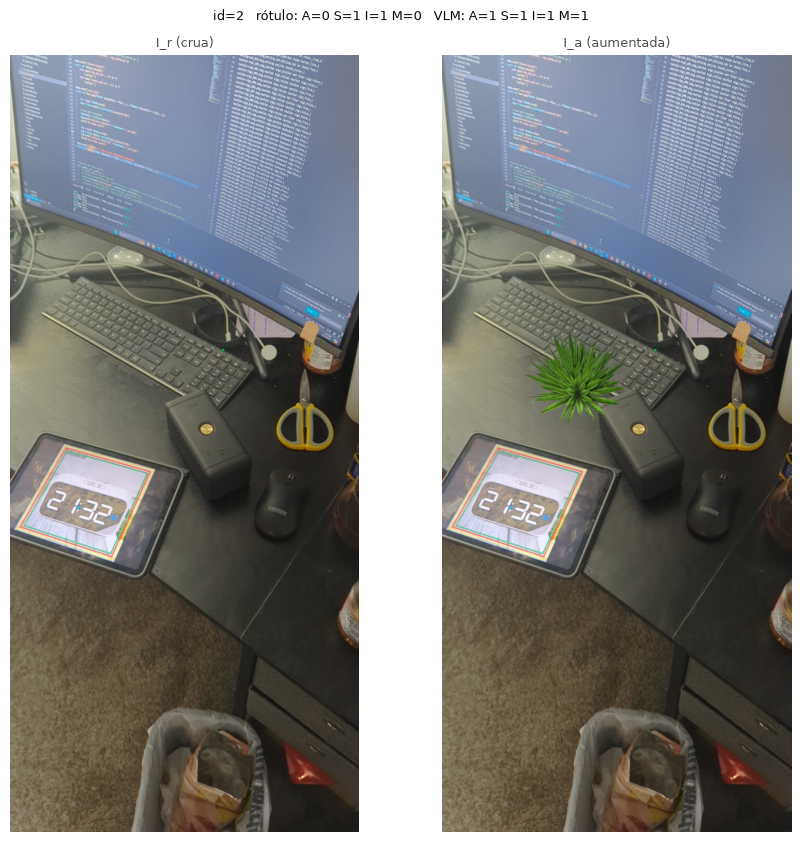

In [14]:
EX_MODEL, EX_VARIANT, EX_CAUSE, N_EXAMPLES = "llava-next-8b-4bit", "paper", "FP:accepted:A", 1

key = (EX_MODEL, EX_VARIANT)
if key in runs:
    df = runs[key].assign(cause=manipulation.error_causes(runs[key]))
    df = df.merge(pd.read_csv(MANIFEST, dtype={"id": str})[["id", "raw_path", "ar_path"]], on="id")
    df[["raw_path", "ar_path"]] = df[["raw_path", "ar_path"]].map(lambda p: str((Path(MANIFEST).parent / p).resolve()))
    sample = df[df["cause"] == EX_CAUSE].head(N_EXAMPLES)
    print(f"{(df['cause'] == EX_CAUSE).sum()} pares com causa {EX_CAUSE}")
    for _, row in sample.iterrows():
        viz.show_manipulation(row)
        plt.show()

## 6. Caminho A: comparação visual das variantes

Um gráfico por modelo. Cada ponto é uma variante. O canto (0, 0) é o ideal, e a diagonal tracejada é
um classificador que ignora a entrada. Uma variante melhora de fato quando o ponto se aproxima do canto;
se ele só desliza ao longo da diagonal, a variante trocou FP por FN. A tabela ao lado traz os mesmos
números.

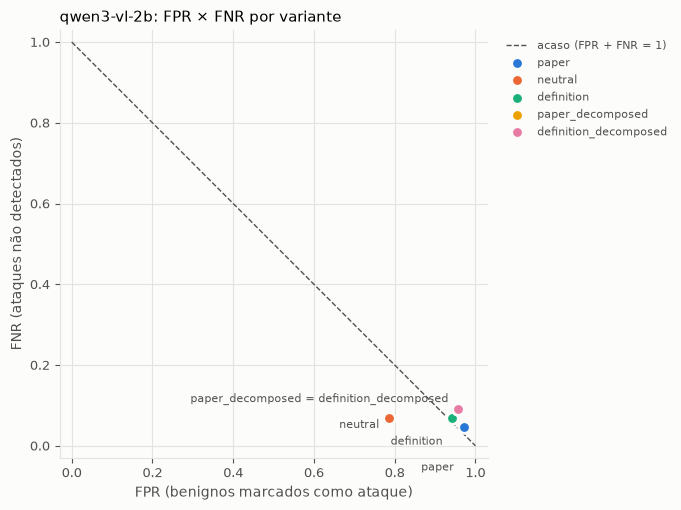

,variant,fpr,fnr
0,paper,0.971429,0.045455
1,neutral,0.785714,0.068182
2,definition,0.942857,0.068182
3,paper_decomposed,0.957143,0.090909
4,definition_decomposed,0.957143,0.090909


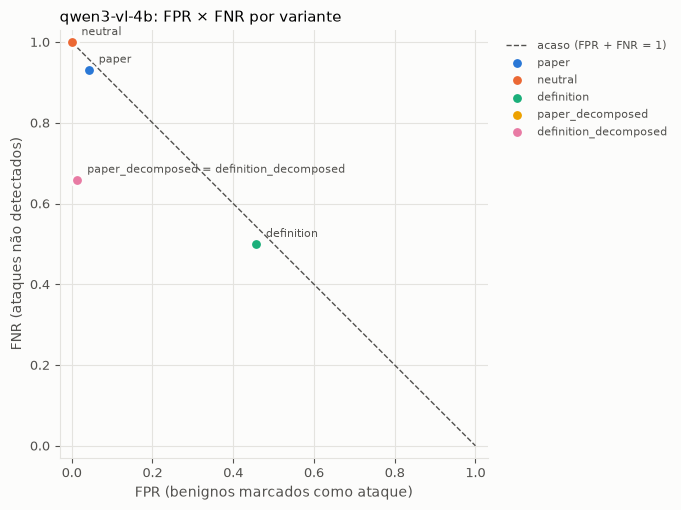

,variant,fpr,fnr
5,paper,0.042857,0.931818
6,neutral,0.000000,1.000000
7,definition,0.457143,0.500000
8,paper_decomposed,0.014286,0.659091
9,definition_decomposed,0.014286,0.659091


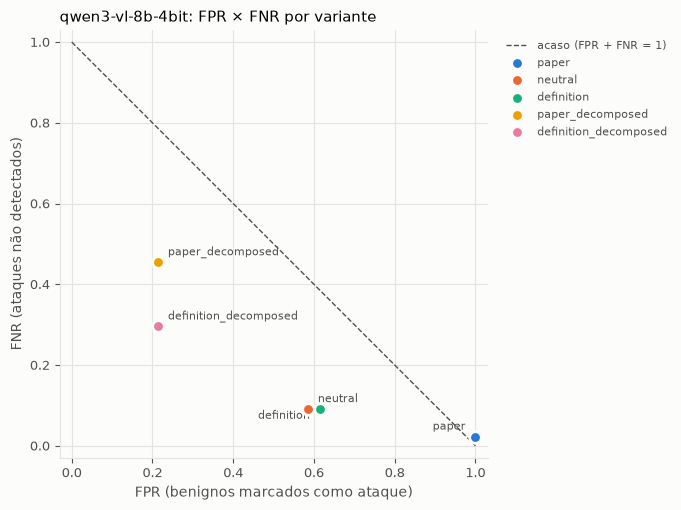

,variant,fpr,fnr
10,paper,1.000000,0.022727
11,neutral,0.585714,0.090909
12,definition,0.614286,0.090909
13,paper_decomposed,0.214286,0.454545
14,definition_decomposed,0.214286,0.295455


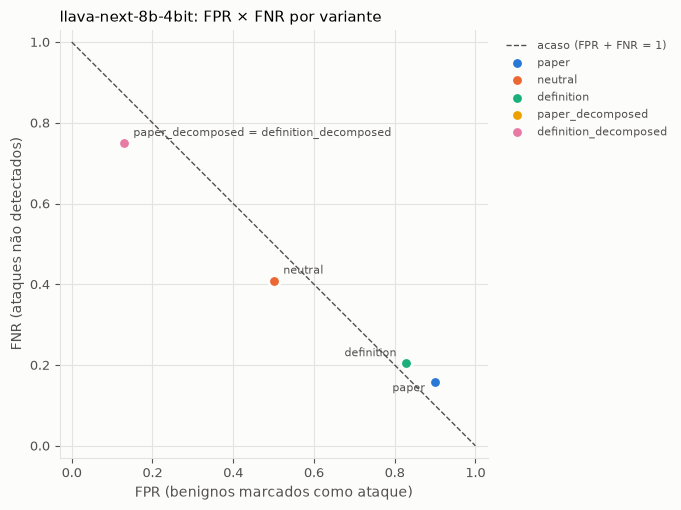

,variant,fpr,fnr
15,paper,0.900000,0.159091
16,neutral,0.500000,0.409091
17,definition,0.828571,0.204545
18,paper_decomposed,0.128571,0.750000
19,definition_decomposed,0.128571,0.750000


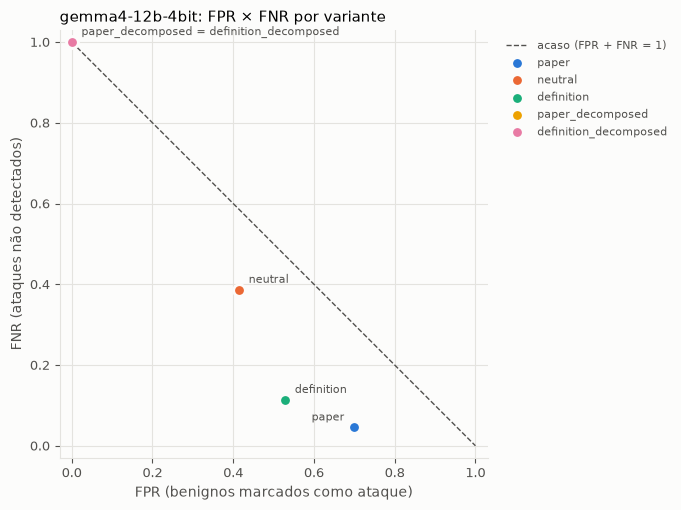

,variant,fpr,fnr
20,paper,0.700000,0.045455
21,neutral,0.414286,0.386364
22,definition,0.528571,0.113636
23,paper_decomposed,0.000000,1.000000
24,definition_decomposed,0.000000,1.000000


In [15]:
for model in MODELS:
    t = errors[errors["model"] == model][["variant", "fpr", "fnr"]]
    if t.empty:
        continue
    fig, table = viz.operating_points(t, f"{model}: FPR × FNR por variante")
    plt.show()
    display(table)

**Leitura.** A soma FPR + FNR mede a distância até a diagonal: vale 1 num detector que ignora a entrada.

- **Ela só cai claramente abaixo de 1 em três casos:**
  - Qwen3-VL-8B nas quatro variantes (0,51 a 0,71; a melhor é `definition_decomposed`);
  - 4B decomposto (0,67);
  - Gemma no modo conjunto (0,64 a 0,80).
- **No 2B e no LLaVA, fica entre 0,85 e 1,06.** As variantes só movem o ponto ao longo da diagonal,
  trocando FP por FN, o que é coerente com o J ≈ 0 desses modelos (5.4).

**Melhor variante por modelo:** a de maior acurácia, como no artigo. Ela alimenta o caminho C2 (seção
7), junto com o prompt do artigo.

In [16]:
best = errors.loc[errors.groupby("model")["accuracy"].idxmax(), ["model", "variant", "accuracy", "precision",
                                                                   "recall"]]
display((best.set_index(["model", "variant"]) * 100).round(1)
        .rename(columns={"accuracy": "acurácia (%)", "precision": "precisão (%)", "recall": "recall (%)"}))
BEST = dict(zip(best["model"], best["variant"]))

,,acurácia (%),precisão (%),recall (%)
model,variant,,,
gemma4-12b-4bit,definition,63.2,51.3,88.6
llava-next-8b-4bit,paper_decomposed,63.2,55.0,25.0
qwen3-vl-2b,neutral,48.2,42.7,93.2
qwen3-vl-4b,paper_decomposed,73.7,93.8,34.1
qwen3-vl-8b-4bit,definition_decomposed,75.4,67.4,70.5


**Comparação entre modelos (melhor variante de cada um).** Teste de McNemar entre as melhores variantes,
nos mesmos 114 pares. A melhor variante foi escolhida olhando os próprios dados, então os números são
otimistas para todos os modelos.

In [17]:
display(reporting.pairwise_comparison(runs, [(m, BEST[m]) for m in MODELS if m in BEST]))

,execução 1,execução 2,acurácia 1,acurácia 2,só 1 acerta,só 2 acerta,McNemar p,resultado
0,qwen3-vl-2b / neutral,qwen3-vl-4b / paper_decomposed,48.2,73.7,27,56,0.002,2 melhor
1,qwen3-vl-2b / neutral,qwen3-vl-8b-4bit / definition_decomposed,48.2,75.4,12,43,0.000,2 melhor
2,qwen3-vl-2b / neutral,llava-next-8b-4bit / paper_decomposed,48.2,63.2,31,48,0.071,sem diferença significativa
3,qwen3-vl-2b / neutral,gemma4-12b-4bit / definition,48.2,63.2,14,31,0.016,2 melhor
4,qwen3-vl-4b / paper_decomposed,qwen3-vl-8b-4bit / definition_decomposed,73.7,75.4,17,19,0.868,sem diferença significativa
5,qwen3-vl-4b / paper_decomposed,llava-next-8b-4bit / paper_decomposed,73.7,63.2,20,8,0.036,1 melhor
6,qwen3-vl-4b / paper_decomposed,gemma4-12b-4bit / definition,73.7,63.2,39,27,0.175,sem diferença significativa
7,qwen3-vl-8b-4bit / definition_decomposed,llava-next-8b-4bit / paper_decomposed,75.4,63.2,28,14,0.044,1 melhor
8,qwen3-vl-8b-4bit / definition_decomposed,gemma4-12b-4bit / definition,75.4,63.2,33,19,0.070,sem diferença significativa
9,llava-next-8b-4bit / paper_decomposed,gemma4-12b-4bit / definition,63.2,63.2,34,34,1.000,sem diferença significativa


**Leitura.**

- **Qwen3-VL-8B (75,4%) e Qwen3-VL-4B (73,7%) empatam (p = 0,87)**, mas por caminhos diferentes: o 8B
  detecta 31 ataques com 15 alarmes falsos; o 4B, 15 ataques com 1 alarme falso.
- Os dois superam o LLaVA (p = 0,04). Contra o Gemma, a vantagem do 8B não é significativa (p = 0,07) e
  a do 4B também não (p = 0,18).
- O 2B é o pior: perde para o 4B, o 8B e o Gemma.
- **Nenhum modelo local alcança o GPT-4o do artigo (82,5%).** Como não temos as respostas do GPT-4o par a
  par, não há teste pareado. O IC95 do 8B, [66,8; 82,4], só encosta nesse valor.

### 6.1 Hipóteses: o que as variantes mostraram

Cada variante testa uma hipótese de `report/analise_fp_fn_manipulacao.md` sobre a origem dos erros.

**H1. O prompt induz um viés de "sim"** ("created by adding some virtual content", "Think creatively").
- **Variante:** `neutral`.
- **Previsão:** a FPR cai.
- **O que se viu:**
  - a FPR caiu em todos os modelos que disparavam: 2B de 97% para 79%, 8B de 100% para 59%, LLaVA de 90%
    para 50%, Gemma de 70% para 41%;
  - a acurácia subiu com significância no 2B, no 8B e no LLaVA;
  - no Gemma, a FNR subiu na mesma medida (de 4,5% para 38,6%);
  - no 8B, parte do ganho vem de menos erros de conclusão (de 44 para 29);
  - o 4B, que já quase não disparava, passou a nunca disparar.
- **Veredito:** confirmada nos modelos com viés de "sim". Mas, sem percepção dos fatores (J ≈ 0), a queda
  de FP vira aumento de FN.

**H2. A conclusão se desconecta das respostas (P1) e cada resposta contamina as outras (P2).**
- **Variante:** `*_decomposed`.
- **Previsão:** os erros de conclusão somem e as respostas por fator ficam mais independentes.
- **O que se viu:**
  - os erros de conclusão somem por construção;
  - a acurácia sobe com significância no 4B (+12,3 p.p.), no 8B (+31,6) e no LLaVA (+24,6); não muda no
    2B;
  - o Gemma vira um detector que nunca dispara;
  - o erro muda de fator: vai para S no 4B e no Gemma, e para A no LLaVA.
- **Veredito:** confirmada em parte. Decompor elimina a P1, mas expõe o julgamento isolado de cada fator,
  que tem o próprio viés em cada modelo.

**H3. O modelo lê I de forma restritiva (P3).**
- **Variante:** `definition` e `definition_decomposed`.
- **Previsão:** menos FN por I.
- **O que se viu:**
  - no modo conjunto, os efeitos vão em direções opostas, sem ganho próprio: o 4B passa a disparar mais em
    todos os fatores, o LLaVA desconecta a conclusão e o Gemma ganha +7,9 p.p. (p = 0,16);
  - no 8B conjunto, o ganho vem da conclusão (de 44 para 17 erros), não de I;
  - no 8B decomposto, os FN por I somem (de 7 para 0), com ganho de 6,1 p.p. sobre `paper_decomposed` (7
    pares a favor, 0 contra, p = 0,016). Mas o J de I não sobe: o modelo passa a aceitar I sempre;
  - no 2B, no 4B e no LLaVA, as duas decompostas são iguais, porque esses modelos já aceitavam I em todos
    os pares.
- **Veredito:** não confirmada como uma leitura melhor de I. O único ganho vem de aceitar I sempre, o que
  funciona porque I = 1 em 90% dos pares.

**C2. O VLM julga mal o alinhamento geométrico.**
- **Variante:** o caminho C2.
- **Previsão:** a FPR cai sem perder ataques.
- **O que se viu e veredito:** ver a seção 7.4.

## 7. Caminho C2: alinhamento geométrico

**A ideia.** O fator A pergunta se o conteúdo virtual está encostado no objeto real, "sem uma separação
significativa". Em vez de perguntar ao VLM, medimos a separação em pixels. O VLM não é chamado de novo:
usamos o nome do objeto que ele já deu e as respostas dele sobre S e I.

**Passo a passo.**
1. **Conteúdo virtual (m_c):** diferença de pixels entre I_a e I_r (os pares são alinhados pixel a
   pixel).
2. **Objeto-chave (m_k):** o nome do objeto dado pelo VLM vai para o Grounding DINO sobre I_r, e a caixa
   de maior escore é segmentada pelo SAM.
3. **Medida `gap_norm`:** menor distância entre o conteúdo e o objeto, dividida pelo tamanho do
   conteúdo. Vale 0 quando eles se tocam.
4. **A geométrico:** A = 1 quando `gap_norm` fica abaixo de um limiar, escolhido por validação cruzada
   (5 partições): cada par é decidido por um limiar ajustado nos outros pares.
5. **Decisão híbrida:** M = A_geo ∧ S_vlm ∧ I_vlm. Onde o objeto não é detectado, vale o A do VLM.

Rodamos o C2 no prompt do artigo e na melhor variante de cada modelo.

In [18]:
alignment_keys = sorted({(m, REFERENCE) for m in MODELS} | set(BEST.items()))
for model, variant in alignment_keys:
    run_dir = OUT_ROOT / "manipulation" / model / variant
    if not (run_dir / "metrics.json").exists() or (run_dir / "alignment" / "metrics.json").exists():
        continue
    if RUN_ALIGNMENT:
        print("alinhamento:", run_dir)
        run_alignment(AlignmentConfig(run_dir=str(run_dir), manifest=MANIFEST))

align = reporting.alignment_summary(OUT_ROOT, alignment_keys)

### 7.1 O C2 melhorou a decisão?

**Esta é a tabela que responde à pergunta.** Cada linha compara, na mesma execução, a decisão híbrida
(com o A geométrico) com duas referências:

- **VLM (`pred`):** a decisão da própria execução. No modo conjunto, é a pergunta 6.
- **A ∧ S ∧ I do VLM:** o E das respostas do próprio VLM. O híbrido só troca A, então é esta a
  comparação que isola o efeito do A geométrico. No modo conjunto, a diferença entre as duas referências
  vem só de trocar a regra de decisão (seção 5.5), e não tem nada de geométrico.

**ganho?** e **ganho do A geométrico?** dizem "melhorou" quando a acurácia híbrida é maior com McNemar
p < 0,05 contra cada referência. A segunda tabela traz precisão, recall, FPR e FNR (VLM → híbrido).

In [19]:
if align.empty:
    print("nenhuma execução com alinhamento ainda (rode a célula anterior com RUN_ALIGNMENT = True)")
else:
    cols = ["model", "variant", "acurácia: VLM → híbrido", "ganho?", "acurácia: A∧S∧I do VLM → híbrido",
            "só híbrido acerta (vs A∧S∧I)", "só A∧S∧I acerta", "McNemar p (vs A∧S∧I)", "ganho do A geométrico?"]
    display(align[cols].round(3))
    display(align[["model", "variant"] + [c for c in align.columns
                                          if "VLM → híbrido" in c and not c.startswith("acurácia")]])

,model,variant,acurácia: VLM → híbrido,ganho?,acurácia: A∧S∧I do VLM → híbrido,só híbrido acerta (vs A∧S∧I),só A∧S∧I acerta,McNemar p (vs A∧S∧I),ganho do A geométrico?
0,gemma4-12b-4bit,definition,63.2 → 65.8,sem diferença significativa,61.4 → 65.8,17,12,0.458,sem diferença significativa
1,gemma4-12b-4bit,paper,55.3 → 59.6,sem diferença significativa,54.4 → 59.6,18,12,0.362,sem diferença significativa
2,llava-next-8b-4bit,paper,38.6 → 52.6,melhorou,38.6 → 52.6,34,18,0.036,melhorou
3,llava-next-8b-4bit,paper_decomposed,63.2 → 62.3,sem diferença significativa,63.2 → 62.3,21,22,1.000,sem diferença significativa
4,qwen3-vl-2b,neutral,48.2 → 60.5,sem diferença significativa,60.5 → 60.5,0,0,1.000,sem diferença significativa
5,qwen3-vl-2b,paper,38.6 → 61.4,melhorou,61.4 → 61.4,0,0,1.000,sem diferença significativa
6,qwen3-vl-4b,paper,61.4 → 61.4,sem diferença significativa,61.4 → 61.4,0,0,1.000,sem diferença significativa
7,qwen3-vl-4b,paper_decomposed,73.7 → 71.1,sem diferença significativa,73.7 → 71.1,0,3,0.250,sem diferença significativa
8,qwen3-vl-8b-4bit,definition_decomposed,75.4 → 75.4,sem diferença significativa,75.4 → 75.4,8,8,1.000,sem diferença significativa
9,qwen3-vl-8b-4bit,paper,37.7 → 78.1,melhorou,75.4 → 78.1,8,5,0.581,sem diferença significativa


,model,variant,precisão: VLM → híbrido,recall: VLM → híbrido,FPR: VLM → híbrido,FNR: VLM → híbrido
0,gemma4-12b-4bit,definition,51.3 → 54.2,88.6 → 72.7,52.9 → 38.6,11.4 → 27.3
1,gemma4-12b-4bit,paper,46.2 → 48.4,95.5 → 70.5,70.0 → 47.1,4.5 → 29.5
2,llava-next-8b-4bit,paper,37.0 → 39.6,84.1 → 43.2,90.0 → 41.4,15.9 → 56.8
3,llava-next-8b-4bit,paper_decomposed,55.0 → 51.4,25.0 → 43.2,12.9 → 25.7,75.0 → 56.8
4,qwen3-vl-2b,neutral,42.7 → nan,93.2 → 0.0,78.6 → 0.0,6.8 → 100.0
5,qwen3-vl-2b,paper,38.2 → nan,95.5 → 0.0,97.1 → 0.0,4.5 → 100.0
6,qwen3-vl-4b,paper,50.0 → 50.0,6.8 → 6.8,4.3 → 4.3,93.2 → 93.2
7,qwen3-vl-4b,paper_decomposed,93.8 → 86.7,34.1 → 29.5,1.4 → 2.9,65.9 → 70.5
8,qwen3-vl-8b-4bit,definition_decomposed,67.4 → 75.0,70.5 → 54.5,21.4 → 11.4,29.5 → 45.5
9,qwen3-vl-8b-4bit,paper,38.1 → 67.3,97.7 → 84.1,100.0 → 25.7,2.3 → 15.9


### 7.2 Por que o C2 ajuda ou não: diagnóstico

O C2 só pode melhorar a decisão se duas coisas forem verdade: a medida geométrica julga A melhor que o
VLM, **e** as respostas do VLM sobre S e I são boas o suficiente. Como a decisão é um E, um "não"
errado em S ou I bloqueia o ataque, seja qual for o A.

- **detected:** em quantos pares o objeto citado pelo VLM foi encontrado.
- **AUC gap_norm:** probabilidade de um par desalinhado (A = 0) ter `gap_norm` maior que um par alinhado
  sorteado ao acaso. 0,5 = a medida não separa os dois grupos; 1 = separa perfeitamente.
- **acerto em A: geométrico × VLM:** fração dos pares (com objeto detectado) em que cada um acerta o
  rótulo de A. É a comparação direta entre a medida e o julgamento do VLM.
- **acurácia híbrida (média ± dp, CV):** a validação cruzada foi repetida 20 vezes com divisões
  diferentes; o desvio mostra o quanto o resultado depende da divisão.

In [20]:
if not align.empty:
    diag = ["model", "variant", "detected"] + [c for c in align.columns if c.startswith("AUC")] + [
        "acerto em A: geométrico", "acerto em A: VLM (mesmos pares)", "acurácia híbrida (média ± dp, CV)"]
    display(align[diag])

,model,variant,detected,AUC gap_norm [IC95],acerto em A: geométrico,acerto em A: VLM (mesmos pares),"acurácia híbrida (média ± dp, CV)"
0,gemma4-12b-4bit,definition,114/114,"0.72 [0.63, 0.82]",0.754386,0.692982,65.4 ± 0.7
1,gemma4-12b-4bit,paper,114/114,"0.70 [0.60, 0.79]",0.728070,0.736842,59.0 ± 1.0
2,llava-next-8b-4bit,paper,110/114,"0.72 [0.62, 0.82]",0.645455,0.600000,52.2 ± 1.6
3,llava-next-8b-4bit,paper_decomposed,104/114,"0.65 [0.54, 0.75]",0.586538,0.413462,61.8 ± 1.9
4,qwen3-vl-2b,neutral,112/114,"0.80 [0.71, 0.88]",0.794643,0.696429,60.5 ± 0.0
5,qwen3-vl-2b,paper,112/114,"0.79 [0.70, 0.87]",0.794643,0.696429,61.4 ± 0.0
6,qwen3-vl-4b,paper,112/114,"0.72 [0.63, 0.81]",0.758929,0.616071,61.4 ± 0.0
7,qwen3-vl-4b,paper_decomposed,101/114,"0.72 [0.63, 0.82]",0.762376,0.633663,71.1 ± 0.0
8,qwen3-vl-8b-4bit,definition_decomposed,97/114,"0.75 [0.65, 0.84]",0.752577,0.742268,75.3 ± 0.4
9,qwen3-vl-8b-4bit,paper,113/114,"0.76 [0.67, 0.85]",0.796460,0.752212,78.5 ± 0.5


O gráfico mostra a medida de uma execução: quanto mais os pontos laranja (A = 0) ficam à direita dos
azuis (A = 1), melhor a separação.

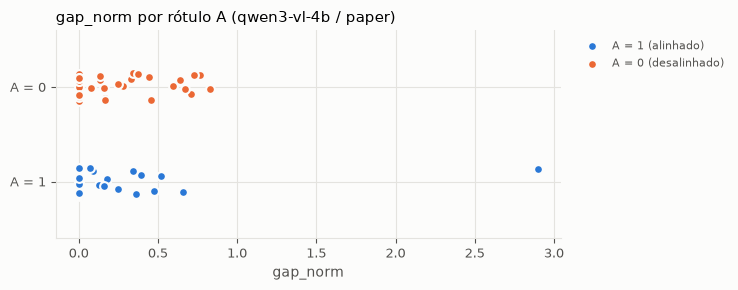

,rótulo,n,mediana,p25,p75
0,A = 1 (alinhado),78,0.000000,0.0,0.000000
1,A = 0 (desalinhado),34,0.147144,0.0,0.425995


In [21]:
EX_RUN = ("qwen3-vl-4b", REFERENCE)
feat_path = OUT_ROOT / "manipulation" / EX_RUN[0] / EX_RUN[1] / "alignment" / "features.csv"
if feat_path.exists() and EX_RUN in runs:
    feats = pd.read_csv(feat_path, dtype={"id": str}).merge(runs[EX_RUN][["id", "A"]], on="id")
    fig, table = viz.gap_strip(feats, "gap_norm", f"gap_norm por rótulo A ({EX_RUN[0]} / {EX_RUN[1]})")
    plt.show()
    display(table)

Pontos cheios: decisão só com o VLM; pontos vazados: a mesma execução com o A geométrico. Um ganho real
aproxima o ponto do canto (0, 0).

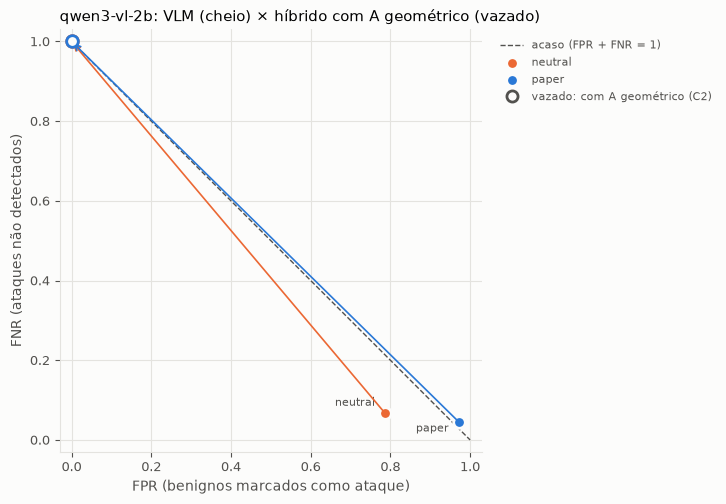

,variant,fpr,fnr,hybrid_fpr,hybrid_fnr
4,neutral,0.785714,0.068182,0.0,1.0
5,paper,0.971429,0.045455,0.0,1.0


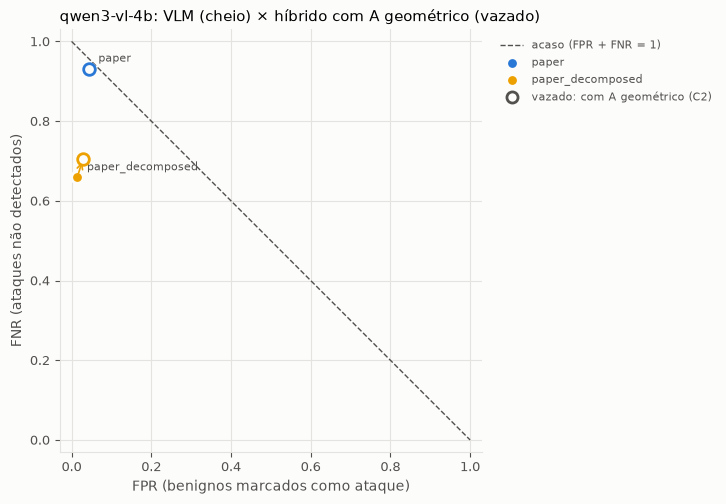

,variant,fpr,fnr,hybrid_fpr,hybrid_fnr
6,paper,0.042857,0.931818,0.042857,0.931818
7,paper_decomposed,0.014286,0.659091,0.028571,0.704545


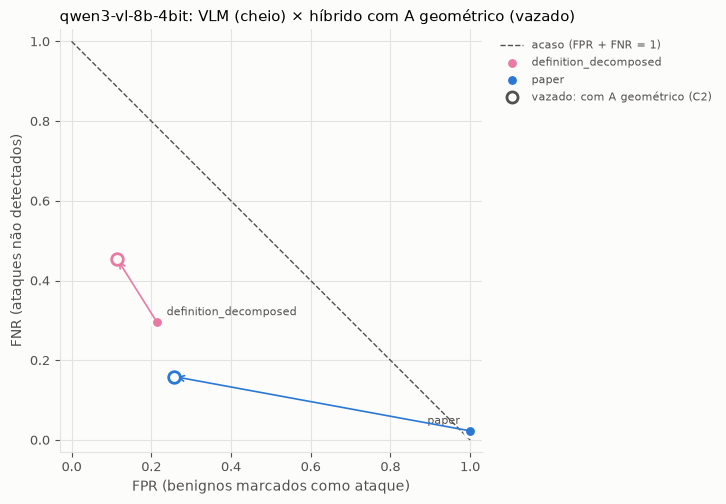

,variant,fpr,fnr,hybrid_fpr,hybrid_fnr
8,definition_decomposed,0.214286,0.295455,0.114286,0.454545
9,paper,1.000000,0.022727,0.257143,0.159091


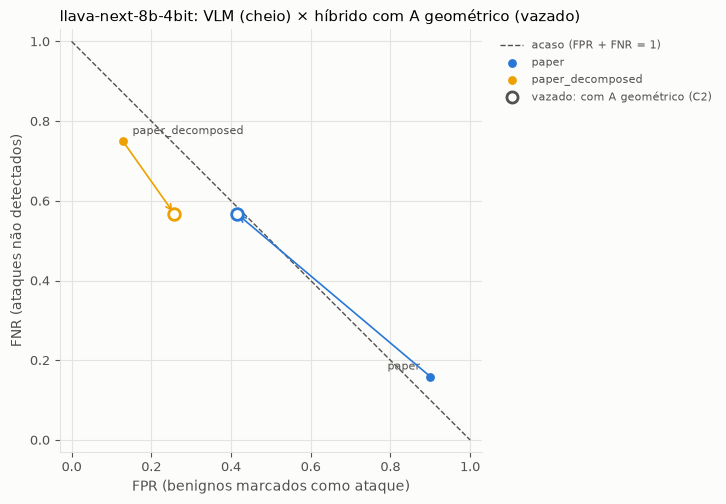

,variant,fpr,fnr,hybrid_fpr,hybrid_fnr
2,paper,0.900000,0.159091,0.414286,0.568182
3,paper_decomposed,0.128571,0.750000,0.257143,0.568182


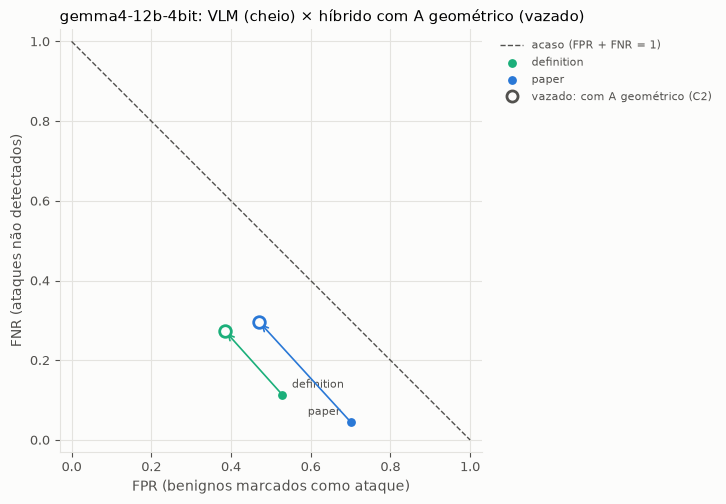

,variant,fpr,fnr,hybrid_fpr,hybrid_fnr
0,definition,0.528571,0.113636,0.385714,0.272727
1,paper,0.700000,0.045455,0.471429,0.295455


In [22]:
for model in MODELS if not align.empty else []:
    t = align[align["model"] == model][["variant", "fpr", "fnr", "hybrid_fpr", "hybrid_fnr"]]
    if t.empty:
        continue
    fig, table = viz.operating_points(t, f"{model}: VLM (cheio) × híbrido com A geométrico (vazado)")
    plt.show()
    display(table)

### 7.3 Exemplos

O par aparece com o objeto detectado (verde) e o conteúdo virtual (laranja). `EX_FILTER` seleciona, por
exemplo, pares desalinhados (A = 0) que o VLM aceitou e o A geométrico corrigiu.

25 pares no filtro


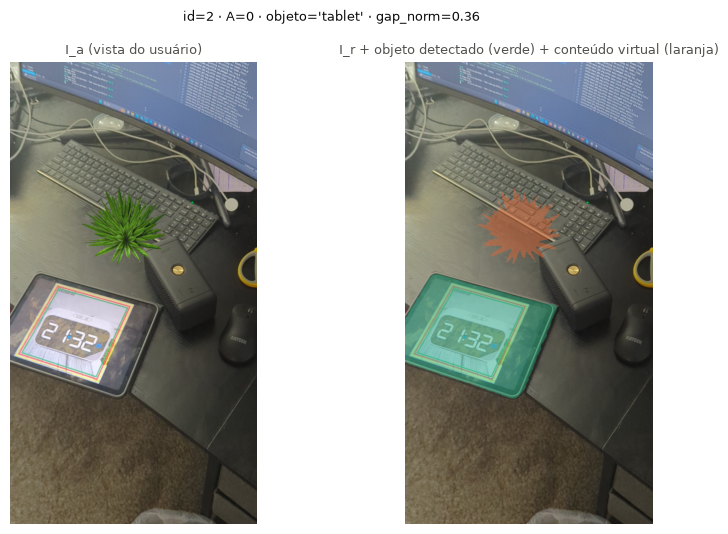

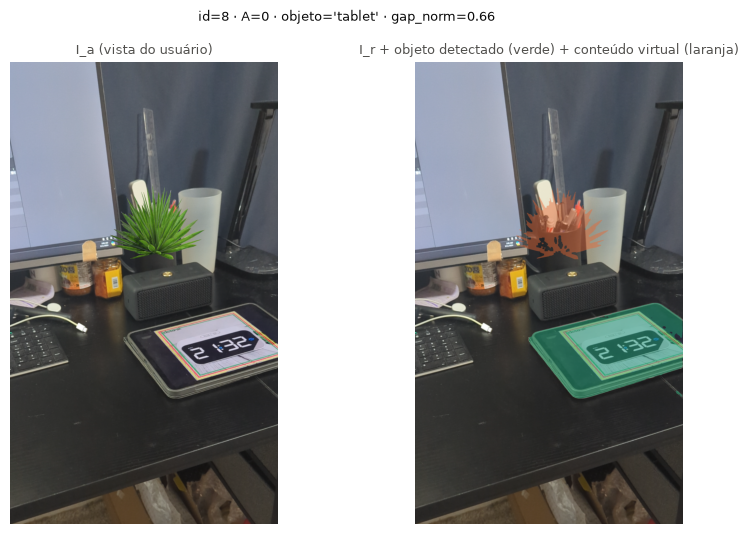

In [23]:
EX_MODEL, EX_VARIANT, N_EXAMPLES = "llava-next-8b-4bit", REFERENCE, 2
pred_path = OUT_ROOT / "manipulation" / EX_MODEL / EX_VARIANT / "alignment" / "predictions.csv"
if pred_path.exists():
    h = pd.read_csv(pred_path, dtype={"id": str})
    h = h.merge(pd.read_csv(MANIFEST, dtype={"id": str})[["id", "raw_path", "ar_path"]], on="id")
    h[["raw_path", "ar_path"]] = h[["raw_path", "ar_path"]].map(lambda p: str((Path(MANIFEST).parent / p).resolve()))
    EX_FILTER = (h["A"] == 0) & (h["pred_A_vlm"] == 1) & (h["pred_A"] == 0)  # A_geo corrigiu o VLM
    print(f"{EX_FILTER.sum()} pares no filtro")
    for _, row in h[EX_FILTER].head(N_EXAMPLES).iterrows():
        mask = pred_path.parent / "key_masks" / f"{row['id']}.png"
        viz.show_alignment(row, str(mask) if mask.exists() else None)
        plt.show()

### 7.4 Leitura do C2

- **A medida geométrica julga A melhor que o VLM.**
  - Em 9 das 10 execuções ela acerta A em mais pares (de 0,59 a 0,80 contra 0,41 a 0,75 do VLM), com AUC
    de 0,65 a 0,80.
  - A exceção é o Gemma `paper`, praticamente empatado (0,73 × 0,74).
- **Isso raramente vira ganho na decisão.**
  - Isolando o A geométrico (comparação com A ∧ S ∧ I), só o LLaVA `paper` melhora com significância: de
    38,6% para 52,6%, p = 0,036.
  - E é uma troca: a FPR cai de 90% para 41%, mas a FNR sobe de 16% para 57%.
- **No `paper`, os ganhos do 2B e do 8B vêm da troca de regra, não da geometria.**
  - **8B:** de 37,7% para 78,1% contra a pergunta 6, mas só de 75,4% para 78,1% contra A ∧ S ∧ I
    (p = 0,58).
  - **2B:** o híbrido é idêntico a A ∧ S ∧ I (61,4%). Como o modelo diz "não" a I em todos os pares,
    nenhum A muda a decisão.
- **Por que um A melhor não ajuda: a decisão é um E.**
  - Onde S ou I do VLM já bloqueiam o ataque, A não importa: I no 2B e no 4B, S no 4B decomposto.
  - Onde o VLM aceita tudo (LLaVA), o A geométrico corta FP, mas também corta ataques, porque a medida
    erra de 20 a 40% dos pares.
- **Veredito da hipótese C2:** confirmada no nível do fator (o VLM julga mal o alinhamento e a geometria
  julga melhor), mas não no nível da decisão. O gargalo está em S e I.

## 8. Resumo

Uma linha por execução: as métricas do artigo, o ganho em relação ao prompt `paper` e, quando existe, o
resultado do C2. Antes de concluir:

- leia algumas respostas brutas das variantes novas (seção 5.8);
- confira que não há respostas ilegíveis em excesso (linha "ilegível" da seção 5.3);
- lembre que as conclusões sobre I se apoiam em só 11 pares benignos.

In [24]:
summary = gain.copy()
if len(align):
    c2 = align[["model", "variant", "acurácia: VLM → híbrido", "ganho?", "ganho do A geométrico?"]].rename(
        columns={"model": "modelo", "variant": "variante", "acurácia: VLM → híbrido": "C2: acurácia VLM → híbrido",
                 "ganho?": "C2: ganho?", "ganho do A geométrico?": "C2: ganho do A geométrico?"})
    summary = summary.merge(c2, on=["modelo", "variante"], how="left")
display(summary)

,modelo,variante,acurácia,precisão,recall,FPR,FNR,Δ acurácia (p.p.),McNemar p,ganho?,C2: acurácia VLM → híbrido,C2: ganho?,C2: ganho do A geométrico?
0,qwen3-vl-2b,paper,38.6,38.2,95.5,97.1,4.5,0.0,NaN,referência,38.6 → 61.4,melhorou,sem diferença significativa
1,qwen3-vl-2b,neutral,48.2,42.7,93.2,78.6,6.8,9.6,0.019,melhorou,48.2 → 60.5,sem diferença significativa,sem diferença significativa
2,qwen3-vl-2b,definition,39.5,38.3,93.2,94.3,6.8,0.9,1.000,sem diferença significativa,NaN,NaN,NaN
3,qwen3-vl-2b,paper_decomposed,37.7,37.4,90.9,95.7,9.1,-0.9,1.000,sem diferença significativa,NaN,NaN,NaN
4,qwen3-vl-2b,definition_decomposed,37.7,37.4,90.9,95.7,9.1,-0.9,1.000,sem diferença significativa,NaN,NaN,NaN
5,qwen3-vl-4b,paper,61.4,50.0,6.8,4.3,93.2,0.0,NaN,referência,61.4 → 61.4,sem diferença significativa,sem diferença significativa
6,qwen3-vl-4b,neutral,61.4,NaN,0.0,0.0,100.0,0.0,1.000,sem diferença significativa,NaN,NaN,NaN
7,qwen3-vl-4b,definition,52.6,40.7,50.0,45.7,50.0,-8.8,0.193,sem diferença significativa,NaN,NaN,NaN
8,qwen3-vl-4b,paper_decomposed,73.7,93.8,34.1,1.4,65.9,12.3,0.003,melhorou,73.7 → 71.1,sem diferença significativa,sem diferença significativa
9,qwen3-vl-4b,definition_decomposed,73.7,93.8,34.1,1.4,65.9,12.3,0.003,melhorou,NaN,NaN,NaN


## 9. Conclusão

Execução completa de 16–17/11/2026: 5 modelos × 5 variantes × 114 pares, decodificação greedy, e o C2
no `paper` e na melhor variante de cada modelo. Os números vêm das seções 4 a 7.

### Principais achados

1. **Com o prompt do artigo, nenhum VLM local resolve a detecção de manipulação.**
   - Todos ficam no nível do detector trivial (61,4%) ou abaixo dele.
   - 2B, 8B e LLaVA disparam em 90 a 100% dos benignos; o 4B quase nunca dispara; o Gemma fica em
     55,3%.
   - O LLaVA (38,6%) reproduz de perto o resultado do artigo (43,0%).

2. **As falhas têm causas diferentes em cada modelo**, e por isso nenhuma variante funciona para todos:
   - conclusão desconectada: 2B e 8B;
   - leitura restritiva de I: 4B;
   - aceitação de A e S: LLaVA e Gemma.

3. **Parte dos modelos não percebe os fatores.**
   - O 2B e o LLaVA têm J ≈ 0 em A, S e I, em todas as variantes: as respostas não dependem da imagem, e
     mudar o prompt só move o viés.
   - Isso é coerente com o desempenho baixo do LLaVA no artigo.

4. **Na família Qwen, o tamanho melhora a percepção, mas não o seguimento da instrução.**
   - O J de A sobe de −0,03 (2B) para 0,48 (8B).
   - Mesmo assim, o 8B tem a pior acurácia no `paper` (37,7%): responde "Yes." na pergunta 6 em 113 de
     114 pares, contradizendo as próprias respostas.
   - Com A ∧ S ∧ I das mesmas respostas, chegaria a 75,4%.

5. **Nenhum modelo discrimina I.**
   - O J de I fica entre −0,30 e +0,25, medido em só 11 pares benignos em I.
   - As variantes que melhoram o resultado fazem o modelo aceitar I sempre, o que funciona porque I = 1
     em 90% dos pares.
   - Na prática, o detector se reduz a A ∧ S. A limitação é dos modelos e também do dataset, que tem
     poucos exemplos para medir I.

6. **Decompor ajuda mais do que mudar palavras, mas não funciona para todos.**
   - O modo decomposto dá as maiores melhorias: 4B +12,3 p.p.; 8B +31,6 e +37,7; LLaVA +24,6. O motivo é
     que ele elimina a etapa de conclusão.
   - Perguntado isoladamente, cada fator tem o próprio viés: o 4B e o Gemma rejeitam S, o LLaVA rejeita
     A. O Gemma decomposto nunca dispara.

7. **Só 3 das 25 execuções superam o detector trivial com significância.**
   - Qwen3-VL-4B decomposto (73,7%, recall 34%), nas duas variantes decompostas.
   - Qwen3-VL-8B `definition_decomposed` (75,4%, precisão 67,4%, recall 70,5%, acurácia balanceada
     74,5%), o único detector equilibrado.
   - Os dois empatam em acurácia (p = 0,87) e ficam abaixo do GPT-4o do artigo (82,5%).
   - Numa análise exploratória (escolhida depois de ver os dados), o 8B com `neutral` e a regra A ∧ S ∧ I
     chega a 80,7%.

8. **O alinhamento geométrico (C2) mede A melhor que o VLM, mas quase nunca melhora a decisão.**
   - A geometria acerta mais A em 9 de 10 execuções, com AUC de 0,65 a 0,80.
   - Isolando o efeito da geometria, só o LLaVA `paper` melhora com significância, e trocando FP por FN.
   - Os ganhos aparentes do 2B e do 8B no `paper` vêm da troca da pergunta 6 por A ∧ S ∧ I.

### O que isso diz sobre os falsos positivos

Os FP da manipulação não têm uma causa única. Eles vêm de três fontes:

- **viés de "sim" do prompt:** só se corrige nos modelos que percebem os fatores;
- **etapa de conclusão:** dá para corrigir tirando a decisão do VLM e calculando-a em código;
- **percepção fraca de A e S:** a geometria corrige A só em parte, e S continua dependendo do VLM.

Nos únicos casos em que os FP caíram sem custar quase todos os ataques (Qwen3-VL-8B), duas condições se
juntaram:

1. um modelo que percebe os fatores (J > 0 em A e S);
2. a decisão tirada da etapa de conclusão do VLM.

O fator I, que define o ataque, segue sem ser medido de forma confiável por nenhum modelo nem pelo
dataset.

### Limitações

- **Tamanho da amostra:** 114 pares (44 ataques), com só 11 benignos com I = 0 e 27 com S = 0.
  Diferenças de poucos pontos não são significativas.
- **Escolha depois de ver os dados:** a melhor variante e a regra A ∧ S ∧ I foram escolhidas olhando os
  resultados, sem conjunto de teste separado. Com 25 execuções, algum p < 0,05 pode ser acaso.
- **Quantização:** 8B, LLaVA e Gemma rodam em 4 bits (NF4), o que pode mudar as respostas em relação aos
  modelos completos.
- **Uma execução por configuração:** decodificação greedy (temperatura 0), sem medir a variância entre
  amostras.
- **Dependências do C2:** usa o nome do objeto dado pelo VLM e a diferença de pixels, que só funciona com
  pares alinhados pixel a pixel.